# 06 Python项目实战之Web开发

本章依据桌面讲义《第6章 - Python项目实战之Web开发》整理。学习路线是先把面向对象的封装、继承、多态补齐，再认识 Web 和 FastAPI，最后完成一个通过网页与 AI 玩猜字游戏的“汉字谜盒”项目。

| 部分 | 讲义内容 | 要解决的问题 |
| --- | --- | --- |
| 面向对象高级 | 封装、继承、重写、多继承、多态、鸭子类型 | 怎样组织有联系的数据和行为、复用代码 |
| 面向对象练习 | 社区图书管理系统 | 怎样用不同会员对象实现不同借书权限 |
| FastAPI 基础 | Web 的组成、接口、路径操作、运行服务 | 怎样让浏览器通过 HTTP 调用 Python 程序 |
| 汉字谜盒 | REST 风格、静态页面、五个核心接口、文件保存 | 怎样把网页、后端、大模型与聊天历史连接起来 |
| 程序优化 | logging、统一异常处理 | 怎样记录运行情况，并向调用者返回一致的错误结果 |

**阅读说明：**保留讲义中的知识、案例、代码、接口格式和复习问题，重复的动画页合并讲解。课件省略的构造方法、没有附带的 JSON 与 static 素材，以及为运行案例补齐的实现，明确标为“补充”；影响运行或理解的错误标为“勘误”。图片内嵌，不设置页内跳转或手写锚点。

本笔记仍以 Markdown 单元格为主，代码块用于阅读和复制。小例子可以放进新的 Code 单元格；完整 Web 项目请按后面的文件名保存成文件，并在终端启动服务，不要把不同阶段的 `main.py` 叠加在同一个文件里。

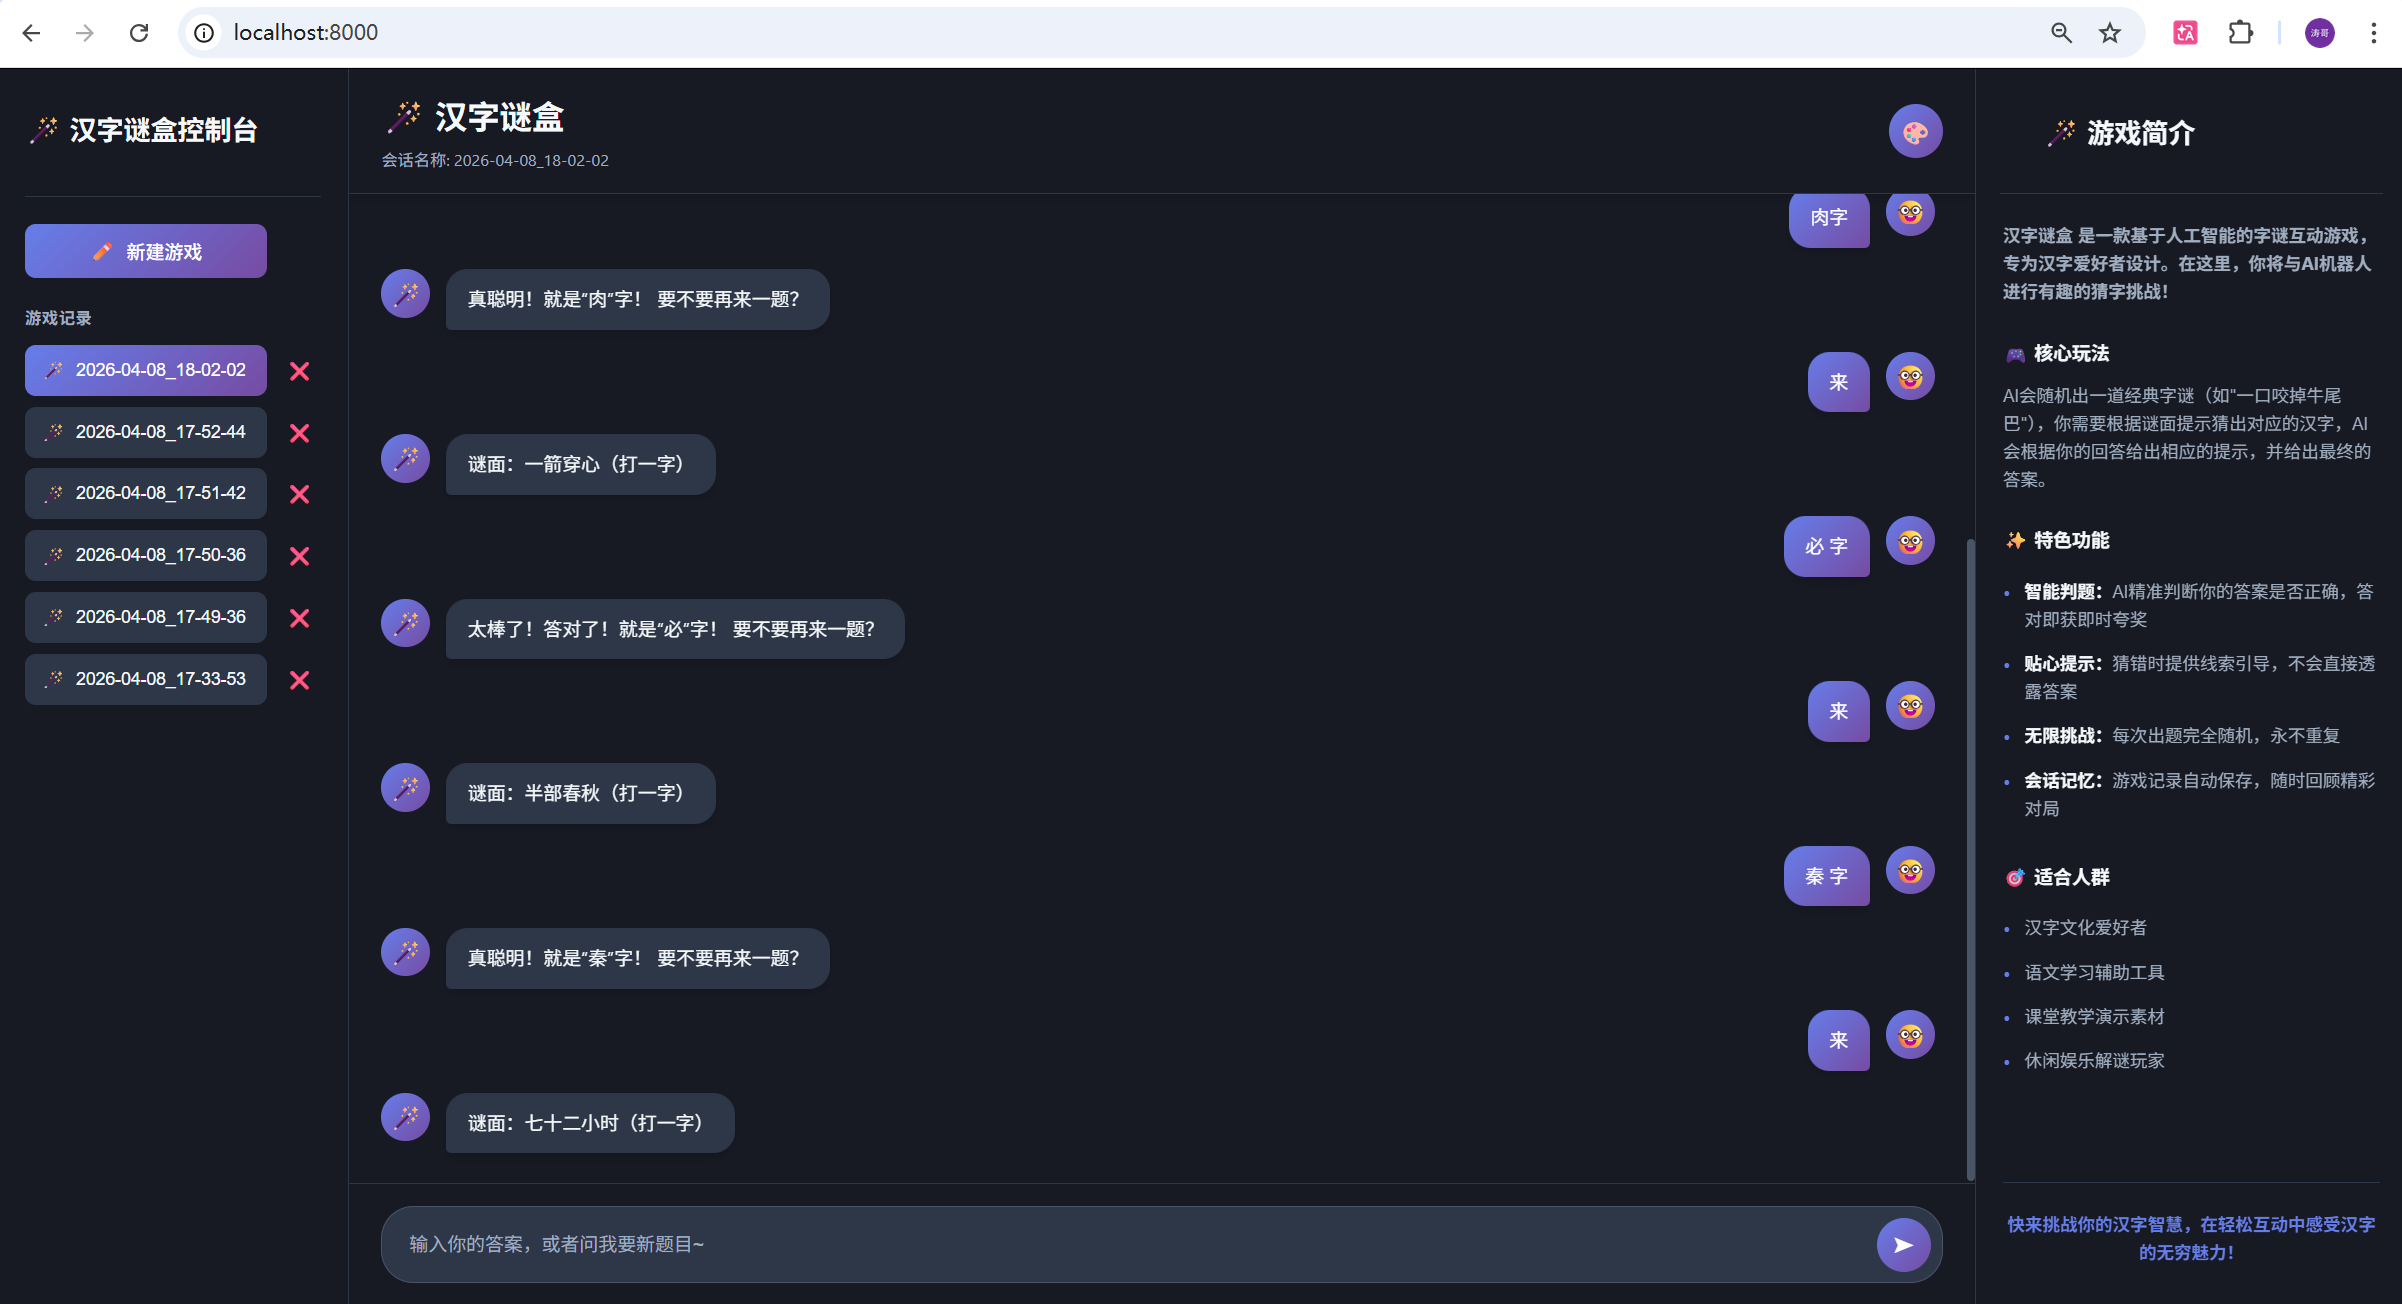

*讲义中的“汉字谜盒”界面：左侧管理会话，中间显示聊天，右侧介绍玩法。*

## 一、先回顾类、对象、属性与方法

### 1. 汽车类回顾

第 4 页使用汽车类复习第二章的面向对象基础。下面将截图中的代码转写成可复制文本；截图里的灰色参数名提示是 IDE 提示，不是 Python 语法。

```python
class Car:
    # 类属性
    wheel = 4
    tax_rate = 0.1

    def __init__(self, c_color, c_brand, c_name, c_price):
        # 实例属性
        self.color = c_color
        self.brand = c_brand
        self.name = c_name
        self.price = c_price

    def running(self):
        print(f"{self.brand} {self.name} 正在高速行驶中...")

    def total_cost(self, discount, rate=0.1):
        total_cost = self.price * discount + rate * self.price
        return total_cost


c1 = Car("白色", "BYD", "汉", 180000)
print(c1.brand)
print(c1.wheel)
print(Car.wheel)
c1.running()
```

| 组成 | 本例 | 含义 |
| --- | --- | --- |
| 类 | `Car` | 对同类事物的数据和行为进行描述 |
| 对象 | `c1` 指向的实例 | 一辆具体的汽车 |
| 类属性 | `wheel、tax_rate` | 定义在类体上，由类提供的属性 |
| 实例属性 | `color、brand、name、price` | 每个对象自己的信息 |
| 初始化方法 | `__init__` | 实例创建时初始化属性 |
| 实例方法 | `running、total_cost` | 通过对象调用，`self` 指向当前对象 |

这里 `print(c1.brand)` 输出 BYD，两次访问 `wheel` 都得到 4。对于本例这种普通属性访问，对象上没有同名实例属性时，会到类及继承链上继续查找。

**补充：**写 `c1.wheel = 6` 通常是在这个实例上新建或修改属性，并不等于把 `Car.wheel` 也改成 6。不要把“类提供的默认值可被多个实例读取”误解成“给任意实例赋值都会同步修改全体实例”。

### 2. 方法的参数与返回值

```python
print(c1.total_cost(0.9))        # 180000.0
print(c1.total_cost(0.9, 0.08))  # 176400.0
```

按课件公式，第一项为车价乘折扣，第二项为原价乘给定税率。此处是方法参数的计算练习，不是完整的真实车辆税费计算规则。

注意：虽然类中定义了 `tax_rate`，这个方法使用的是参数 `rate`；如果没有主动读取 `self.tax_rate` 或 `Car.tax_rate`，修改类属性不会自动改变 `rate` 的默认值。

后面各节会重新定义 `Car`，分别突出不同知识点；类名相同不代表几个代码块会自动合并。

## 二、封装：提供接口，隐藏内部细节

### 1. 从汽车零件到汽车

封装是把数据（属性）和操作数据的方法捆绑到一个独立的类中，并隐藏内部实现细节，只对外提供必要的功能。

课件用汽车的零件、整车和驾驶室作类比：驾驶员通过方向盘、踏板等接口操作汽车，不需要每次开车都直接操作发动机或燃油分配机构。

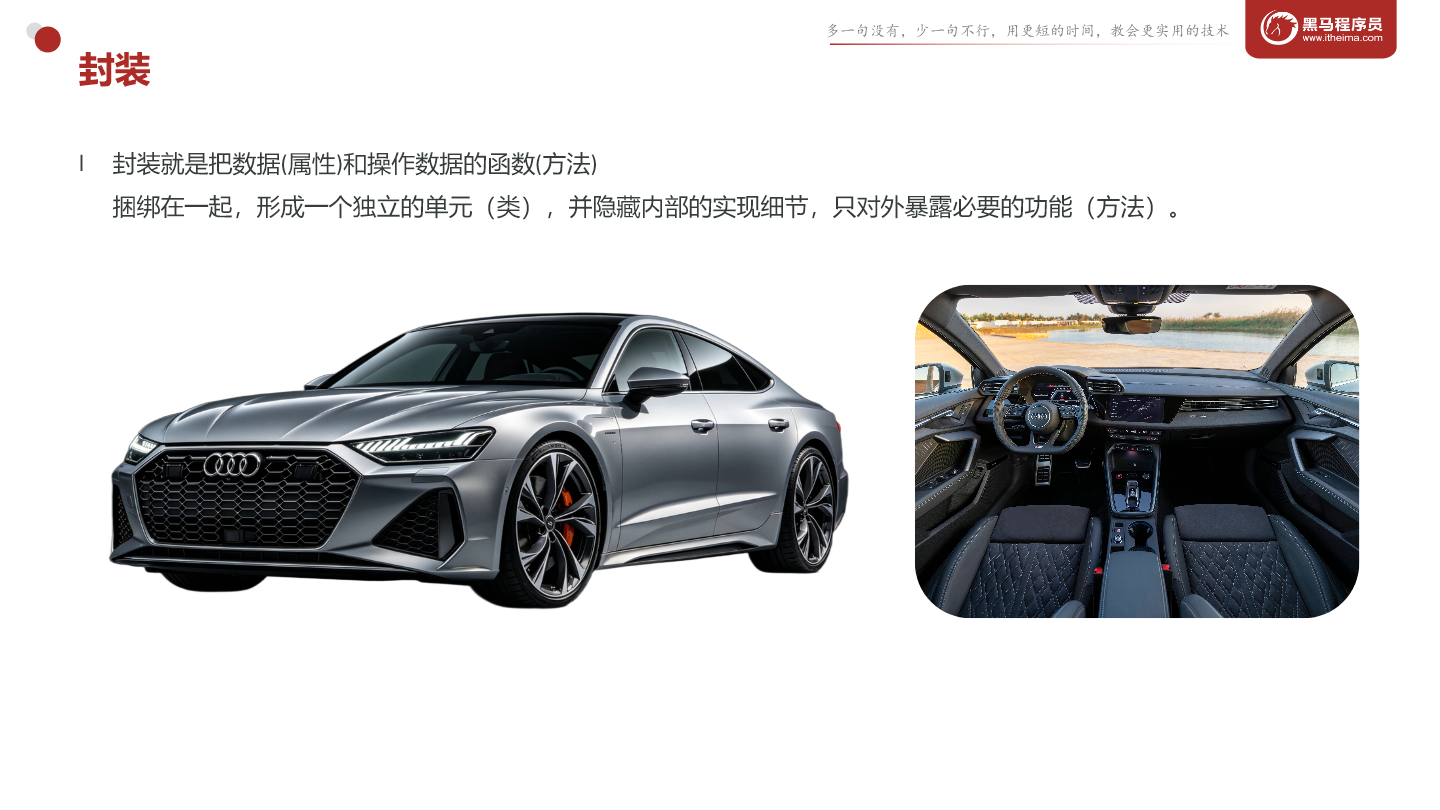

*讲义中的封装类比：整车组织内部部件，对使用者提供明确的操作入口。*

封装包含两层意思：

1. 把同一对象的数据和行为放在一起，形成清晰的责任边界。
2. 通过对外方法组织使用方式，减少调用者直接依赖内部细节。

它不等于“所有属性都必须改成私有”，也不只是机械地添加双下划线。

### 2. 公共属性与公共方法

课件首先定义所有成员都直接对外可见的汽车类：

```python
class Car:
    # 类属性 (所有实例对象共享的)
    wheel = 4 # 轮胎数量
    tax_rate = 0.1 # 购置税税率

    def __init__(self, c_color, c_brand, c_name):
        # 实例属性
        self.color = c_color
        self.brand = c_brand
        self.name = c_name

    def start(self):  # 启动
        print(f'{self.brand} {self.name} 正在启动...')

    def stop(self):  # 停止
        print(f'{self.brand} {self.name} 停止行驶...')
```

在类外可以访问颜色、品牌、名称，也可以调用启动、停止：

```python
car = Car("白色", "BYD", "汉")
print(car.color)
car.start()
car.stop()
```

### 3. 私有属性与私有方法

课件增加了车主与控制燃油分配的方法：

```python
class Car:
    # 类属性 (所有实例对象共享的)
    wheel = 4 # 轮胎数量
    tax_rate = 0.1 # 购置税税率

    def __init__(self,c_color,c_brand,c_name,c_owner):
        # 实例属性
        self.color = c_color
        self.brand = c_brand
        self.name = c_name
        self.__owner = c_owner

    def start(self):  # 启动
        print(f'{self.brand} {self.name} 正在启动...')

    def stop(self):  # 停止
        print(f'{self.brand} {self.name} 停止行驶...')
  
    def __control_fuel(self):
        print(f'{self.brand} {self.name} 控制燃油分配...')
```

`__owner` 与 `__control_fuel` 使用两个前导下划线，意图是只在该类的实现中使用；`color、brand、name、start、stop` 仍是公共成员。

**勘误与补充：Python 并非严格访问控制。**双前导下划线主要触发“名称改写”：例如 `Car` 中的 `__owner` 会改写为 `_Car__owner`。因此类外直接写 `car.__owner` 通常会报 `AttributeError`，但不能把它理解成不可绕过的权限或加密机制。

```python
car = Car("白色", "BYD", "汉", "张三")
print(car.name)
print(hasattr(car, "__owner"))       # False
print(hasattr(car, "_Car__owner"))   # True
```

这个例子用来说明机制，不建议业务代码依赖改写后的名字访问内部成员。

| 命名 | 通常表达的含义 |
| --- | --- |
| `name` | 公共成员 |
| `_name` | 约定为内部使用，单下划线本身不阻止访问 |
| `__name` | 触发名称改写，减少外部误用以及继承中的名字冲突 |
| `__init__` | Python 特殊方法，两端双下划线，不是这里的“私有属性”写法 |

### 4. 通过公共方法使用内部功能

课件中的私有方法只是定义出来，并没有在 `start` 中调用。下面是补充的调用示例：

```python
class Car:
    def __init__(self, owner):
        self.__owner = owner

    def __control_fuel(self):
        print("控制燃油分配")

    def start(self):
        self.__control_fuel()
        print("车辆已启动")

    def owner_name(self):
        return self.__owner


car = Car("张三")
car.start()
print(car.owner_name())
```

调用者只需要知道 `start` 负责启动。将来燃油控制流程调整，只要公共方法的约定不变，调用者通常不必跟着修改。

本节复习：封装把什么放在一起？属性与方法；私有成员怎么写？使用双前导下划线；什么时候适合使用？当某些实现细节不希望成为调用者依赖的公共接口时；是否能靠双下划线保护密码文件？不能。

## 三、继承：提取共同部分

### 1. 为什么需要继承

课件先用生活中的继承作引入，再把汽车分成通用汽车 `Car`、燃油汽车 `FuelCar` 与电动汽车 `ElectricCar`。

如果三个类都分别写颜色、品牌、型号、启动、停止、行驶，就会产生大段重复代码。共同功能改一次，需要同步修改多个位置。

继承描述类之间的关系：子类基于父类复用已有行为，也可以增加或调整自己的行为。

```text
Car
    ├─ FuelCar
    └─ ElectricCar
```

父类也叫基类，子类也叫派生类。这里的关系可以理解为“燃油汽车是一种汽车”“电动汽车是一种汽车”。

### 2. 讲义完整代码

```python
class Car:
    def __init__(self, c_color, c_brand, c_model):
        self.color = c_color
        self.brand = c_brand
        self.model = c_model
    
    def start(self):  # 启动
        print(f'{self.brand} {self.model} 正在启动...')
    def stop(self):  # 停止
        print(f'{self.brand} {self.model} 停止行驶...')
    def run(self): # 行驶
        print(f'{self.brand} {self.model} 正在行驶...')
```

```python
class FuelCar(Car):
    pass
```

```python
class ElectricCar(Car):
    pass
```

`class FuelCar(Car):` 的括号中指定父类。`pass` 是占位语句，表示子类目前没有增加新代码，不表示它无法使用父类行为。

```python
fuel = FuelCar("黑色", "BMW", "X5")
electric = ElectricCar("白色", "BYD", "汉")

print(fuel.brand, fuel.model)
fuel.start()
fuel.run()
electric.start()
electric.stop()
```

这两个子类没有重写 `__init__`，构造对象时会使用继承的初始化方法，于是都具有颜色、品牌和型号等实例属性。

### 3. 如何理解“私有成员不继承”

课件把规则简化为“继承父类公共属性和方法，不含私有”。**必要说明：**父类初始化建立的内部状态不会从子类对象中消失，父类的方法仍然可以使用它；只是子类不能用自己的 `self.__属性` 直接指代父类同名的双下划线属性，因为名称改写使用了不同的类名。

```python
class Parent:
    def __init__(self):
        self.__value = 10

    def read_value(self):
        return self.__value


class Child(Parent):
    pass


child = Child()
print(child.read_value())  # 10，继承的方法仍能访问父类维护的状态
```

继承也不是在定义子类时把父类源码复制一份，而是通过属性和方法的查找规则复用父类实现。

## 四、方法重写与 super

### 1. 什么是重写

当父类某个方法不能满足子类需求时，子类可以定义同名方法，提供自己的实现，这就是方法重写。

课件把“补充燃料”作为公共行为，再让燃油汽车具体执行加油。**勘误：**第 18 页初始化的是 `self.name`，但 `charge` 使用了 `self.model`，直接运行可能出现属性不存在。下面统一使用 `name`，其余逻辑保留。

```python
class Car:
    def __init__(self, c_color, c_brand, c_name):
        self.color = c_color
        self.brand = c_brand
        self.name = c_name

    def start(self):
        print(f"{self.brand} {self.name} 正在启动...")

    def stop(self):
        print(f"{self.brand} {self.name} 停止行驶...")

    def charge(self):
        print(f"{self.brand} {self.name} 正在补充燃料...")


class FuelCar(Car):
    def charge(self):
        print(f"{self.brand} {self.name} 正在加油...")


car = FuelCar("黑色", "BMW", "X5")
car.charge()
```

最后调用的是子类的 `charge`，输出“BMW X5 正在加油…”。

### 2. 在子类中继续执行父类逻辑

如果子类并不是完全替换，而是在共同逻辑后增加自己的动作，可以使用 `super`：

```python
class FuelCar(Car):
    def charge(self):
        super().charge()
        print(f"{self.brand} {self.name} 正在加油...")


car = FuelCar("黑色", "BMW", "X5")
car.charge()
```

这次依次输出父类的“补充燃料”和子类的“加油”。

讲义给出两种调用方式：

| 写法 | 特点 |
| --- | --- |
| `super().charge()` | 按方法解析顺序继续寻找对应实现，不手动传 self |
| `Car.charge(self)` | 明确调用 Car 上的方法，需手动传入当前对象 |

在当前简单单继承例子中，两者都可以调用父类逻辑；在多继承中，它们的含义不能一概等同。

### 3. 重写初始化方法时保留公共初始化

**补充：后面的 VIP 会员会用到。**

```python
class ElectricCar(Car):
    def __init__(self, color, brand, name, battery_capacity):
        super().__init__(color, brand, name)
        self.battery_capacity = battery_capacity


electric = ElectricCar("白色", "BYD", "汉", 85)
print(electric.brand, electric.name, electric.battery_capacity)
```

子类一旦定义自己的 `__init__`，Python 不会再自动额外执行父类的 `__init__`；需要公共初始化时，应主动调用。否则后面访问 `brand` 等父类本来创建的属性时，可能发现它们根本没有建立。

## 五、多继承与方法解析顺序

### 1. 多继承的写法

一个子类可以同时继承多个父类：

```text
class 子类名(父类名1, 父类名2, 父类名3):
    类体
```

**补充示例：**

```python
class Camera:
    def take_photo(self):
        print("拍照")

    def start(self):
        print("启动相机")


class MusicPlayer:
    def play_music(self):
        print("播放音乐")

    def start(self):
        print("启动播放器")


class Phone(Camera, MusicPlayer):
    pass


phone = Phone()
phone.take_photo()
phone.play_music()
phone.start()
print(Phone.__mro__)
print(Phone.mro())
```

`Phone` 可以使用拍照与播放音乐两个行为。在这个简单结构中，`start` 首先找到 `Camera` 的实现。

### 2. 不要只记“永远找第一个父类”

MRO 是 **Method Resolution Order**，即方法解析顺序。上例为：

```text
Phone → Camera → MusicPlayer → object
```

课件说“默认优先使用第一个父类中的同名成员”，适合解释简单情况。**补充：**复杂的多层、多继承结构使用完整的 MRO 规则，不是对第一个父类一路递归到底；`super()` 也是沿 MRO 继续查找。

因此遇到同名方法或协作式调用，应查看 `类名.__mro__` 或 `类名.mro()`。不要把多继承当成无条件拼接几个类的代码。

## 六、多态与鸭子类型

### 1. 同一次调用，不同对象，不同行为

多态指同一个调用入口，对不同对象表现出不同的行为。课件使用 `charge`：燃油汽车加油，电动汽车充电。

课件第 22 页省略了构造方法，却传入多项参数，第 23 页截图又使用另一组构造参数。下面补齐并统一为“品牌、型号、颜色、车主”四个参数，让示例可以完整运行：

```python
class Car:
    def __init__(self, brand, model, color, owner):
        self.brand = brand
        self.model = model
        self.color = color
        self.owner = owner

    def charge(self):
        print("正在补充燃料...")


class FuelCar(Car):
    def charge(self):
        print("燃油汽车正在加油...")


class ElectricCar(Car):
    def charge(self):
        print("电动汽车正在充电...")


def handle_charge(car: Car):
    car.charge()


handle_charge(FuelCar("BMW", "X5", "黑色", "张三"))
handle_charge(ElectricCar("BYD", "汉", "白色", "李四"))
```

`handle_charge` 内部只有一句 `car.charge()`，但运行结果随传入的对象变化。共同调用逻辑无需反复写“如果是油车就……如果是电车就……”。

### 2. 类型提示不是运行时的强制限制

`car: Car` 表达“期望接收 Car 类型对象”的类型提示，便于阅读、IDE 补全和静态检查。Python 本身不会仅因为这个注解，就自动拒绝所有非 Car 对象。

这与后面 FastAPI 利用类型提示和 Pydantic 主动验证 HTTP 请求，是两个层面的机制：一个是普通 Python 注解，另一个是框架读取注解后执行验证。

### 3. 鸭子类型

讲义的表述是：“如果它走路像鸭子，叫起来像鸭子，那么就可以把它当作鸭子。”编程中关注的是对象有没有所需的行为，而不是一定属于哪个类。

下面补齐课件省略的初始化方法：

```python
class Dog:
    def __init__(self, name, age):
        self.name = name
        self.age = age

    def swimming(self):
        print(f"{self.age} 岁的 {self.name} 正在游泳...")


class Duck:
    def __init__(self, name, age):
        self.name = name
        self.age = age

    def swimming(self):
        print(f"{self.age} 岁的 {self.name} 正在游泳...")


class Pig:
    def __init__(self, name, age):
        self.name = name
        self.age = age

    def swimming(self):
        print(f"{self.age} 岁的 {self.name} 正在游泳...")


def go_swimming(duck):
    duck.swimming()


go_swimming(Dog("旺财", 4))
go_swimming(Duck("唐老鸭", 2))
go_swimming(Pig("佩奇", 1))
```

三个类没有继承关系，但都提供可调用的 `swimming()`，所以可以使用同一个函数。参数名 `duck` 只是名字，并不会限制传入的一定是 Duck 对象。

如果传入的对象没有该方法，就会报错；如果方法需要不同的必填参数，也不能直接兼容。“有相同行为”还包含调用方式和语义能够满足要求。

| 对比 | 继承体系中的多态 | 鸭子类型 |
| --- | --- | --- |
| 是否要求共同父类 | 课件此种示例有共同父类 | 不要求 |
| 共同依据 | 父类约定的行为，由子类实现或重写 | 对象具备调用方需要的行为 |
| 本章例子 | FuelCar、ElectricCar 的 charge | Dog、Duck、Pig 的 swimming |

本节复习：多态的变化发生在哪里？实际对象对应的方法实现；鸭子类型检查的重点是什么？对象能做什么；普通类型提示是否自动执行请求验证？不会，后面是框架额外完成的工作。

## 七、面向对象练习：社区图书管理系统

### 1. 完整需求

社区图书馆需要一个支持普通会员与 VIP 会员的管理系统。

核心功能：

1. 会员通过卡号和密码登录。
2. 借阅仍有库存的图书。
3. 归还已经借阅的图书。
4. 查看当前会员的借阅列表。
5. 退出系统。

借阅规则：

| 会员类型 | 最大同时借阅数量 |
| --- | ---: |
| 普通会员 | 3 本 |
| VIP 会员 | `6 + VIP 等级` 本 |
| 默认 VIP 等级 | 1，即默认上限 7 本 |

必须先登录成功，才能操作系统。库存不足，或当前已借数量达到会员上限，都不能继续借书。

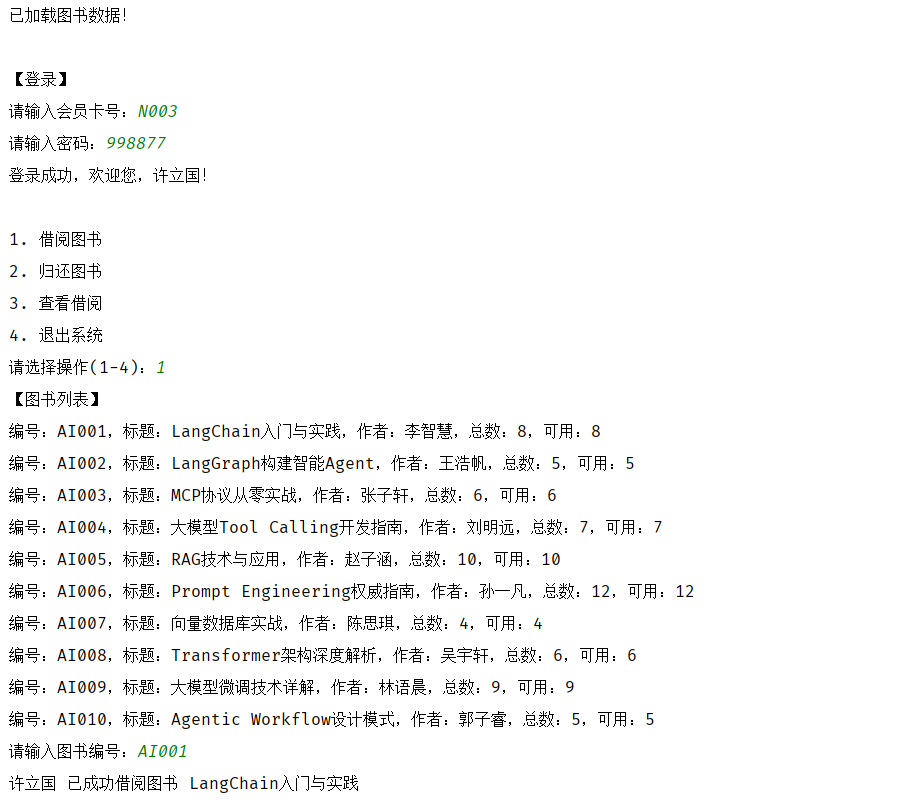

*讲义中的交互效果：卡号登录、功能菜单、图书清单与借阅结果。书目是课程演示数据。*

### 2. 按讲义设计类

| 类 | 责任 | 体现的面向对象知识 |
| --- | --- | --- |
| Member | 保存共同会员信息，校验密码，提供借阅上限接口 | 封装共同属性和行为 |
| NormalMember | 给出普通会员上限 3 | 继承、重写 |
| VipMember | 保存等级，给出 6 + 等级的上限 | 继承、super、重写 |
| Book | 保存编号、标题、作者、总量、可用库存 | 把图书状态组织成对象 |
| LibrarySystem | 加载数据，管理当前登录会员，协调借还书 | 组合会员与图书，组织业务流程 |

系统借书时只调用 `member.borrow_limit()`，不需要在每次借书时重复判断“普通还是 VIP”。这就是多态在案例中的作用。

课件提到 `members.json` 与 `books.json`，但没有附带文件内容或完整源码。以下数据结构与实现为**补充参考答案**，保留课件的会员规则和菜单功能。

### 3. 文件结构和数据准备

```text
library_demo/
    prepare_library_data.py
    library.py
    data/
        members.json
        books.json
```

把下面代码保存为 `prepare_library_data.py`，运行一次：

```python
import json
from pathlib import Path

# 补充教学数据；书目名称取自课件截图，会员字段结构由参考实现定义。
data_dir = Path(__file__).resolve().parent / "data"
data_dir.mkdir(exist_ok=True)
members = [
    {"card_id": "N003", "name": "许立国", "password": "998877",
     "type": "normal", "borrowed": []},
    {"card_id": "V001", "name": "李明", "password": "123456",
     "type": "vip", "level": 1, "borrowed": []},
]
book_rows = [
    ("AI001", "LangChain入门与实践", "李智慧", 8),
    ("AI002", "LangGraph构建智能Agent", "王浩帆", 5),
    ("AI003", "MCP协议从零实战", "张子轩", 6),
    ("AI004", "大模型Tool Calling开发指南", "刘明远", 7),
    ("AI005", "RAG技术与应用", "赵子涵", 10),
    ("AI006", "Prompt Engineering权威指南", "孙一凡", 12),
    ("AI007", "向量数据库实战", "陈思琪", 4),
    ("AI008", "Transformer架构深度解析", "吴宇轩", 6),
    ("AI009", "大模型微调技术详解", "林语晨", 9),
    ("AI010", "Agentic Workflow设计模式", "郭子睿", 5),
]
books = [
    {"book_id": book_id, "title": title, "author": author, "total": total}
    for book_id, title, author, total in book_rows
]
for filename, data in [("members.json", members), ("books.json", books)]:
    destination = data_dir / filename
    if destination.exists():
        print("保留已有数据：", destination)
        continue
    destination.write_text(
        json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print("已创建：", destination)
```

它不会覆盖已有文件。示例普通会员是 `N003 / 998877`；补充的 VIP 会员是 `V001 / 123456`，默认等级为 1。

这里为展示课程登录流程，使用明确可见的教学密码。`__password` 只是在类中组织内部数据，并不对 JSON 文件里的明文密码加密；正式账户系统应使用密码哈希等机制，这不是本例要实现的账户体系。

`books.json` 保存书目总量；`members.json` 中的 `borrowed` 保存尚未归还的图书编号。启动时用总量减去全部会员的借阅数量，得到可用库存。这样借还书只需更新会员记录，避免把库存和借阅记录分别写进两份文件却只成功一份。

### 4. 完整参考实现

保存为 `library.py`：

```python
import json
from pathlib import Path


class Member:
    def __init__(self, card_id, name, password, borrowed=None):
        self.card_id = card_id
        self.name = name
        self.__password = password
        self.borrowed = list(borrowed or [])

    def check_password(self, password):
        return self.__password == password

    def borrow_limit(self):
        raise NotImplementedError("请由具体会员类型提供借阅上限")

    def to_dict(self):
        return {
            "card_id": self.card_id,
            "name": self.name,
            "password": self.__password,
            "borrowed": self.borrowed.copy(),
        }


class NormalMember(Member):
    def borrow_limit(self):
        return 3

    def to_dict(self):
        return {**super().to_dict(), "type": "normal"}


class VipMember(Member):
    def __init__(self, card_id, name, password, borrowed=None, level=1):
        super().__init__(card_id, name, password, borrowed)
        if not isinstance(level, int) or level < 1:
            raise ValueError("VIP 等级必须为正整数")
        self.level = level

    def borrow_limit(self):
        return 6 + self.level

    def to_dict(self):
        return {**super().to_dict(), "type": "vip", "level": self.level}


class Book:
    def __init__(self, book_id, title, author, total):
        self.book_id = book_id
        self.title = title
        self.author = author
        self.total = total
        self.available = total


class LibrarySystem:
    def __init__(self, data_dir):
        self.data_dir = Path(data_dir)
        self.member_file = self.data_dir / "members.json"
        rows = json.loads(self.member_file.read_text(encoding="utf-8"))
        self.members = {}
        for row in rows:
            if row["type"] == "normal":
                member = NormalMember(
                    row["card_id"], row["name"], row["password"], row["borrowed"]
                )
            elif row["type"] == "vip":
                member = VipMember(
                    row["card_id"], row["name"], row["password"],
                    row["borrowed"], row.get("level", 1),
                )
            else:
                raise ValueError("未知会员类型")
            if member.card_id in self.members:
                raise ValueError("会员卡号重复")
            self.members[member.card_id] = member

        rows = json.loads(
            (self.data_dir / "books.json").read_text(encoding="utf-8")
        )
        self.books = {}
        for row in rows:
            book = Book(row["book_id"], row["title"], row["author"], row["total"])
            if book.book_id in self.books or book.total < 0:
                raise ValueError("图书编号重复或总量不合法")
            self.books[book.book_id] = book

        # 可用库存由总量减去全部借阅记录得到，避免两份文件分别更新而不一致。
        for member in self.members.values():
            for book_id in member.borrowed:
                if book_id not in self.books:
                    raise ValueError("借阅记录引用了不存在的图书")
                self.books[book_id].available -= 1
        if any(book.available < 0 for book in self.books.values()):
            raise ValueError("借阅记录超过图书总量")
        self.current_member = None

    def login(self, card_id, password):
        self.current_member = None
        member = self.members.get(card_id)
        if member is None or not member.check_password(password):
            raise ValueError("卡号或密码不正确")
        self.current_member = member
        return member

    def require_login(self):
        if self.current_member is None:
            raise ValueError("请先登录")
        return self.current_member

    def save_members(self):
        rows = [member.to_dict() for member in self.members.values()]
        temporary = self.member_file.with_suffix(".tmp")
        temporary.write_text(
            json.dumps(rows, ensure_ascii=False, indent=2), encoding="utf-8"
        )
        temporary.replace(self.member_file)

    def borrow_book(self, book_id):
        member = self.require_login()
        if book_id not in self.books:
            raise ValueError("图书不存在")
        book = self.books[book_id]
        if len(member.borrowed) >= member.borrow_limit():
            raise ValueError("已达到当前会员的借阅上限")
        if book.available <= 0:
            raise ValueError("图书库存不足")
        member.borrowed.append(book_id)
        book.available -= 1
        try:
            self.save_members()
        except OSError:
            member.borrowed.pop()
            book.available += 1
            raise
        return f"{member.name} 已成功借阅《{book.title}》"

    def return_book(self, book_id):
        member = self.require_login()
        if book_id not in member.borrowed:
            raise ValueError("你没有借阅这本书")
        position = member.borrowed.index(book_id)
        member.borrowed.pop(position)
        self.books[book_id].available += 1
        try:
            self.save_members()
        except OSError:
            member.borrowed.insert(position, book_id)
            self.books[book_id].available -= 1
            raise
        return f"已归还《{self.books[book_id].title}》"

    def my_borrowings(self):
        member = self.require_login()
        return [self.books[book_id] for book_id in member.borrowed]

    def logout(self):
        self.current_member = None


def run():
    system = LibrarySystem(Path(__file__).resolve().parent / "data")
    print("已加载图书和会员数据")
    while True:
        card_id = input("请输入会员卡号（输入 q 退出）：").strip()
        if card_id.lower() == "q":
            return
        password = input("请输入密码：").strip()
        try:
            member = system.login(card_id, password)
            print(f"登录成功，欢迎 {member.name}，借阅上限 {member.borrow_limit()} 本")
            break
        except ValueError as exc:
            print(exc)

    while True:
        print("\n1. 借阅图书  2. 归还图书  3. 查看借阅  4. 退出系统")
        choice = input("请选择操作：").strip()
        try:
            if choice == "1":
                for book in system.books.values():
                    print(book.book_id, book.title, book.author,
                          "总数", book.total, "可用", book.available)
                print(system.borrow_book(input("请输入图书编号：").strip()))
            elif choice == "2":
                print(system.return_book(input("请输入图书编号：").strip()))
            elif choice == "3":
                borrowed = system.my_borrowings()
                if not borrowed:
                    print("当前没有借阅")
                for book in borrowed:
                    print(book.book_id, book.title)
            elif choice == "4":
                system.logout()
                print("已退出系统")
                return
            else:
                print("请选择 1—4")
        except (ValueError, OSError) as exc:
            print("操作未完成：", exc)


if __name__ == "__main__":
    run()
```

运行：

```powershell
python prepare_library_data.py
python library.py
```

### 5. 顺着一次借阅读代码

```text
登录：卡号查找会员 → 核对密码 → 保存当前会员
借书：确认已登录 → 查找图书 → 检查借阅上限 → 检查库存
      → 增加借阅记录 → 扣减可用库存 → 保存
还书：确认已登录 → 确认本人借过 → 移除一条借阅记录
      → 增加可用库存 → 保存
```

| 关键代码 | 用途 |
| --- | --- |
| `self.__password` | 把密码校验逻辑留在 Member 内部 |
| `super().__init__(...)` | VIP 先完成共同会员初始化，再增加等级 |
| `member.borrow_limit()` | 根据实际会员类型得到不同上限 |
| `list(borrowed or [])` | 每个会员获得自己的借阅列表，避免共享同一可变默认值 |
| `require_login()` | 统一检查是否已登录 |
| `json.loads / json.dumps` | JSON 数据与 Python 对象相互转换 |
| `ensure_ascii=False` | 保存时直接保留中文字符 |
| `temporary.replace(...)` | 先写临时文件，再替换目标，降低写入中断造成半份 JSON 的概率 |

**补充实现约定：**本例按“册数”计上限，允许在有库存时借同一书目的多册，每次归还一册；课件没有规定同一书目只能借一本。程序是单进程的本地练习，不考虑多个图书管理员同时修改同一文件。

### 6. 练习检查

| 操作 | 预期 |
| --- | --- |
| 卡号不存在或密码错误 | 不进入功能菜单 |
| 普通会员已借 3 本，再借第 4 本 | 提示达到上限，库存不变 |
| 默认 VIP 已借 6 本，再借第 7 本 | 有库存时成功 |
| 默认 VIP 已借 7 本，再借第 8 本 | 提示达到上限 |
| 借没有库存的书 | 失败，不新增借阅记录 |
| 归还本人没有借的书 | 失败，不能凭空增加库存 |
| 归还本人借阅的一册 | 借阅数减少 1、库存增加 1 |
| 退出并重新启动 | 从 JSON 恢复借阅状态和相应库存 |

先独立尝试实现需求，再对照参考答案查看类的职责与调用关系。重点是让对象承担明确行为，而不是仅把原来的函数放进一个大类。

## 八、Web 网站由什么组成

### 1. 浏览器中看到的页面只是其中一部分

Web 即 World Wide Web，通常称为万维网。课件用电商、课程网站和汉字谜盒说明：用户在浏览器里输入地址，就可以访问页面和相应服务。

Web 是建立在网络之上的一种信息与应用服务形式，不能简单等同于整个互联网。本章主要研究浏览器通过 HTTP 与 Python 服务端交互。

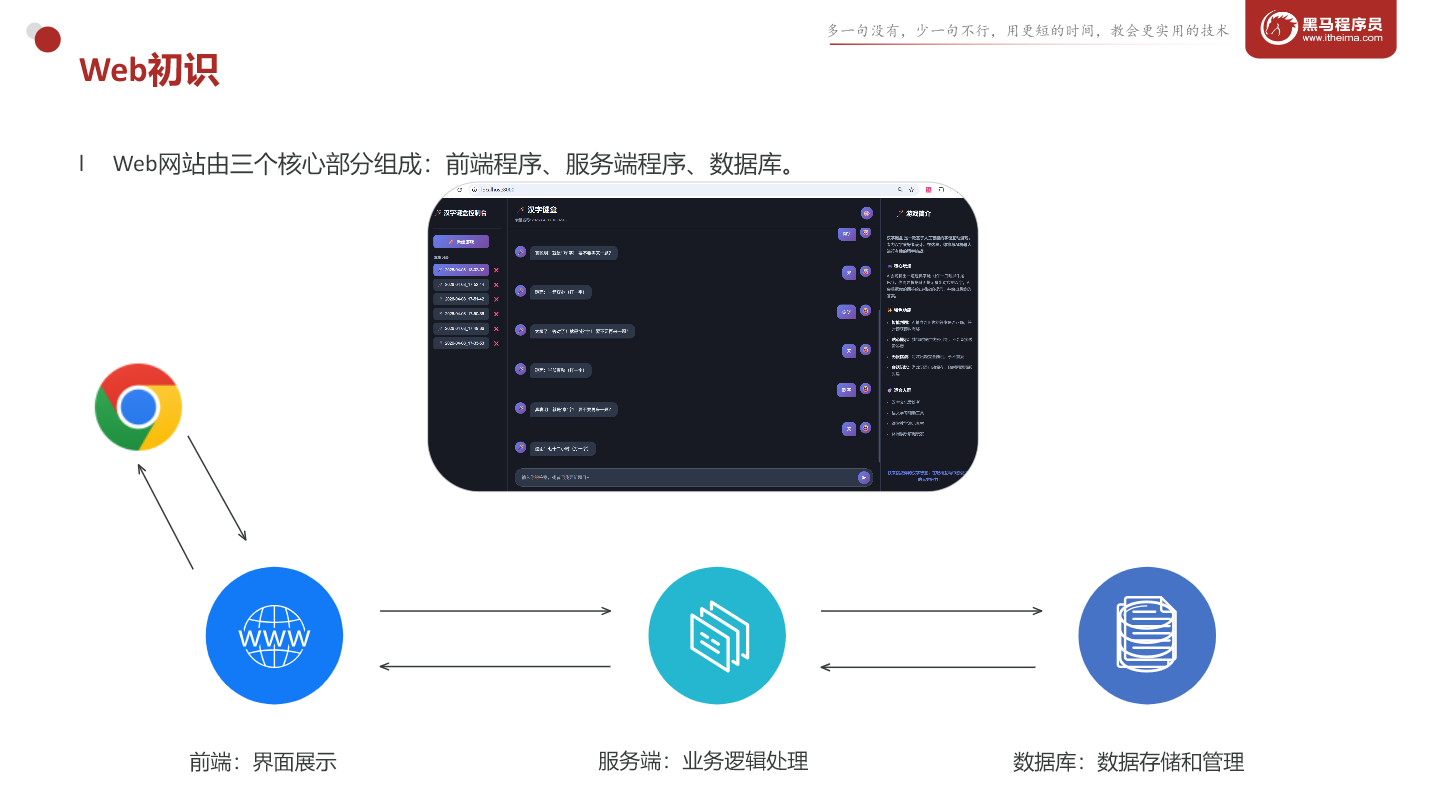

*讲义的 Web 组成示意：前端负责展示，服务端处理业务，存储层保存数据。*

| 部分 | 责任 | 汉字谜盒中的例子 |
| --- | --- | --- |
| 前端程序 | 显示界面，接收用户操作，发送请求 | 会话列表、聊天气泡、输入框、发送按钮 |
| 服务端程序 | 执行业务规则，与其他服务通信 | 创建会话、读取历史、请求 DeepSeek、保存回复 |
| 数据存储 | 持久保存需要保留的数据 | 每个会话对应的 JSON 文件 |

课件先介绍常见的“前端—服务端—数据库”结构，再把本案例的数据库替换成文件。不是所有网站都必须使用数据库；这里用 JSON 文件帮助理解数据保存流程。

### 2. 前端的三个组成部分

| 技术 | 主要职责 | 本例 |
| --- | --- | --- |
| HTML | 内容与结构 | 标题、按钮、输入框、消息区域 |
| CSS | 外观与布局 | 深色背景、左右分栏、聊天气泡 |
| JavaScript | 交互与行为 | 监听点击、发送 fetch 请求、更新页面 |

服务端可以使用 Python 的 Django、Flask 或 FastAPI。本章选择 FastAPI，实现路径、请求参数处理与 JSON 响应。

### 3. 一次网页交互的过程

```text
用户点击发送
    → JavaScript 收集消息与会话 ID
    → 发出 POST /api/chat
    → FastAPI 校验参数并执行对话逻辑
    → 服务端读取历史、调用模型、写回文件
    → 返回 JSON
    → JavaScript 把回复显示成聊天气泡
```

浏览器中出现新气泡，不意味着数据一定已经保存；要看服务端是否成功写入持久化文件。反过来，只写好 Python 接口，也不会自动拥有课件中的前端界面。

本节复习：HTML 管结构，CSS 管样式，JavaScript 管交互；后端处理业务；文件或数据库负责在程序重启后仍保留数据。

## 九、FastAPI 入门

### 1. 框架、接口与 HTTP

FastAPI 是一个使用标准 Python 类型提示构建 API 服务的 Web 框架。它负责把请求交给对应函数，并处理参数、验证与响应等工作。

API 是 Application Programming Interface，即应用程序编程接口，可以理解为对外提供的功能入口。对调用者而言，重要的是入口地址、请求方式、参数和返回结果，不必知道服务端内部怎样实现。

课件提供的中文站点是 [fastapi.org.cn](https://fastapi.org.cn/)；官方文档入口为 [FastAPI 官方文档](https://fastapi.tiangolo.com/zh/)。

**保留课件备注示例：**第 36 页用天气接口说明“发送请求、获得数据”的过程：

[Open-Meteo 天气请求示例](https://api.open-meteo.com/v1/forecast?latitude=40.060303&longitude=116.343387&current_weather=true&timezone=Asia/Shanghai)

| 地址部分 | 含义 |
| --- | --- |
| `/v1/forecast` | 请求路径 |
| `latitude=40.060303` | 纬度 |
| `longitude=116.343387` | 经度 |
| `current_weather=true` | 该示例使用的当前天气参数 |
| `timezone=Asia/Shanghai` | 时区参数 |

这是课件中的请求格式示例，不把它当成本笔记已经获取的实时天气。问号后面的参数通过 `&` 连接，属于查询参数；后面聊天接口还会使用路径参数和 JSON 请求体。

### 2. 安装依赖

**补充：完整安装步骤。**在项目选定的 Python 环境执行：

```powershell
python -m pip install "fastapi[standard]" httpx
```

`fastapi[standard]` 包含常见开发依赖，便于使用课件中的 FastAPI CLI 与 Uvicorn；`httpx` 用于后面的模型 HTTP 请求和接口测试。Pydantic 是 FastAPI 依赖的验证库，无需在这里另选一套互不兼容的版本。

可以查看当前解释器与版本：

```python
import sys
import fastapi
import pydantic

print(sys.executable)
print(fastapi.__version__)
print(pydantic.__version__)
```

### 3. 讲义的第一个服务

保存为一个独立项目中的 `main.py`：

```python
from fastapi import FastAPI

# 创建FastAPI实例
app = FastAPI()

# 定义功能接口
@app.get("/")
def root():
    return {"message": "Hello World"}

# 定义功能接口
@app.get("/users")
def get_users():
    return [{"id": 1, "name": "Alice", "age": 18},
            {"id": 2, "name": "Bob", "age": 20}]
```

课件的四步对应到代码：

1. `from fastapi import FastAPI`：导入框架。
2. `app = FastAPI()`：创建应用对象。
3. 使用 `@app.get(...)` 注册路径操作函数。
4. 启动服务器，让请求真正到达这个应用。

| 代码 | 含义 |
| --- | --- |
| `@app.get("/")` | 当 GET 请求匹配根路径时，调用下面的函数 |
| `def root()` | 处理该请求的 Python 函数，名字本身不决定 URL |
| `return {"message": "Hello World"}` | 返回的数据由框架转换成 JSON 响应 |
| `@app.get("/users")` | 定义查询用户列表的入口 |

`@` 是装饰器语法。这里只需先理解：它把“请求方式 + 路径”与一个函数关联起来。写好函数还不等于服务正在监听端口。

### 4. 启动服务的三种方式

课件给出 FastAPI CLI 与 Uvicorn CLI：

```powershell
fastapi dev main.py
```

或者：

```powershell
python -m uvicorn main:app --reload --host 127.0.0.1 --port 8000
```

`main:app` 中，`main` 是 Python 模块名，不带 `.py`；`app` 是模块中的应用对象名。`--reload` 用于开发时监测代码修改并重新加载。

课件还给出直接从 Python 启动的方法，把以下内容放到 `main.py` 末尾：

```python
# 启动FastAPI服务器
if __name__ == "__main__":
    import uvicorn
    uvicorn.run(app, host="0.0.0.0", port=8000)
```

然后运行：

```powershell
python main.py
```

三种方法选一种，不要同时占用同一个 8000 端口。Uvicorn 是运行 FastAPI 应用的 ASGI 服务器；FastAPI 负责应用逻辑，两者职责不同。

**补充：地址含义。**`127.0.0.1` 是本机回环地址；`0.0.0.0` 表示监听所有网络接口，是监听配置，不是通常在浏览器中输入的目标地址。按本地学习方式，在浏览器打开 `http://127.0.0.1:8000`。

### 5. 访问与调试

| 地址 | 用途 |
| --- | --- |
| `http://127.0.0.1:8000/` | 查看 Hello World JSON |
| `http://127.0.0.1:8000/users` | 查看 Alice、Bob 的列表 |
| `http://127.0.0.1:8000/docs` | FastAPI 自动生成的交互式接口文档 |
| `http://127.0.0.1:8000/openapi.json` | 机器可读的接口描述 |

**补充：**在 `/docs` 中展开接口，点击 Try it out，填写参数，再点 Execute，可以看到请求与响应。浏览器地址栏一般发 GET，不能靠直接输入地址完成 POST 或 DELETE 测试。

课件第 38 页截图的 `/users` 另用三位中文姓名演示列表响应，其结构如下：

```python
users = [
    {"id": 1, "name": "张三"},
    {"id": 2, "name": "李四"},
    {"id": 3, "name": "王五"},
]
```

它与前一页的 Alice、Bob 是两组示例数据，知识点都是“Python 列表中放字典，可以响应为 JSON 数组”。

本节复习：FastAPI 负责定义接口，Uvicorn 运行应用；装饰器声明路径和方法；函数返回值成为响应数据；开发服务器运行后通常会一直占用当前终端，使用 Ctrl+C 停止。

## 十、开发规范：REST 风格

### 1. 用资源与 HTTP 方法描述操作

REST 是 Representational State Transfer，常译为表述性状态转移。RESTful API 是遵循这种架构风格设计的接口服务。本章重点是：

- URL 表达资源。
- HTTP 方法表达对资源的操作。

课件的传统形式：

| URL | 方法 | 含义 |
| --- | --- | --- |
| `/user/getById?id=1` | GET | 查询 ID 为 1 的用户 |
| `/user/saveUser` | POST | 新增用户 |
| `/user/updateUser` | POST | 修改用户 |
| `/user/deleteUser?id=1` | GET | 删除 ID 为 1 的用户 |

如果每个人给新增操作分别取名 `addUser、add、insertUser、insert、saveUser、save`，接口会缺少一致的表达规则。使用 GET 删除数据还会把有副作用的行为混进普通读取请求。

课件对应的 REST 风格：

| URL | 方法 | 含义 |
| --- | --- | --- |
| `/users/1` | GET | 查询 ID 为 1 的用户 |
| `/users/1` | DELETE | 删除 ID 为 1 的用户 |
| `/users` | POST | 新增用户 |
| `/users` | PUT | 课件用它演示修改用户 |

以上路径都可以加上统一的地址前缀 `http://localhost:8000`。

**补充：**具体修改 ID 为 1 的用户，通常使用 `PUT /users/1`，更清楚地标识目标；`PUT /users` 则要另外明确整个集合或请求体中的目标语义。PUT 通常表达整体替换，局部修改常使用 PATCH，这里知道区别即可。

### 2. 名称与约定

课件建议使用资源名的复数形式，如 `users、books、items`。相同 URL 可以根据不同 HTTP 方法对应不同操作，例如：

```text
GET    /api/sessions   查询会话集合
POST   /api/sessions   在集合中创建会话
```

REST 是一种风格和约定，并不是所有接口都必须机械地套成同一形式；不过“可以按实际情况设计”不等于忽视 HTTP 方法本身的语义。

### 3. 讲义复习题

| 方法 | 本章对应操作 |
| --- | --- |
| GET | 查询 |
| POST | 新增，或执行约定的处理操作 |
| PUT | 修改 / 替换 |
| DELETE | 删除 |

题目 `DELETE http://localhost:8000/users/5` 表达删除 ID 为 5 的用户。

URL 中通常不再额外写 `deleteUser`，因为 DELETE 已经说明动作；“请求方法”和“路径”共同确定接口，而不是只看路径字符串。

## 十一、汉字谜盒：项目目标与基础环境

### 1. 项目做什么

汉字谜盒是一款基于 AI 的汉字猜谜游戏。AI 出一道单字谜面，例如“一箭穿心”，用户猜汉字；AI 根据回答给出提示、判断答案，并在适当的时候说明谜底。

课件的界面包含五项核心功能：

| 功能 | 用户操作 |
| --- | --- |
| 新建会话 | 点击新建，获得一段新的游戏记录 |
| 与 AI 交互 | 输入开始、猜测、提示请求或答案 |
| 查询会话列表 | 在侧边栏看到已有游戏记录 |
| 加载指定会话 | 点击旧会话，继续查看或对话 |
| 删除会话 | 点击会话旁边的删除按钮 |

程序还要在页面首次打开且不存在历史会话时，自动创建一个会话。

### 2. 文件组织

课件要求把资料中的 `static` 目录复制到项目，再创建 `main.py`。当前桌面只有 PPT，未发现配套 static、members.json 或 books.json 文件。本笔记后面给出补充素材与参考页面，便于独立练习。

完整参考项目采用：

```text
hanzi_box/
    main.py
    store.py
    ai_client.py
    static/
        index.html
    sessions/
        2026-04-12_13-18-03.json
        ...
```

`sessions` 保存会话文件，会由程序自动创建；示例文件名只说明结构，不需要手动创建那个指定日期的文件。

### 3. 首页与静态资源

第 48 页的核心逻辑是返回 HTML，并挂载 static。下面补齐课件省略的 `StaticFiles` 导入，使用脚本所在目录定位文件：

```python
from pathlib import Path
from fastapi import FastAPI
from fastapi.responses import FileResponse
from fastapi.staticfiles import StaticFiles

BASE_DIR = Path(__file__).resolve().parent
app = FastAPI(title="汉字谜盒")
app.mount(
    "/static",
    StaticFiles(directory=BASE_DIR / "static"),
    name="static",
)

@app.get("/")
def root():
    return FileResponse(BASE_DIR / "static/index.html")
```

这段应保存到 `main.py`，并确保 `static/index.html` 已存在。后面完整项目中的 `main.py` 会包含这些代码，不需要再重复添加一遍。

| 写法 | 含义 |
| --- | --- |
| `FileResponse(...)` | 把文件内容作为响应发送给浏览器 |
| `app.mount("/static", ...)` | 把 /static 路径及其子路径交给静态文件应用处理 |
| `directory=...` | 磁盘上静态文件所在的目录 |
| `name="static"` | 应用内部引用这个挂载点的名字，不是文件路径 |
| `Path(__file__).resolve().parent` | 当前 Python 文件所在的目录 |

访问 `/` 时返回首页；访问 `/static/index.html` 时由静态资源挂载处理。如果 HTML 再引用 `/static/style.css`、`/static/app.js`，浏览器还会分别请求这些文件。

课件使用相对路径 `FileResponse("static/index.html")`，要求启动时的工作目录正确。这里改为基于文件位置的绝对路径，避免换个目录启动就找不到素材。

## 十二、先约定数据结构与五个接口

### 1. 一个会话对应一个 JSON 文件

课件示例文件名为 `2026-04-12_13-18-03.json`：

```json
{
  "current_session": "2026-04-12_13-18-03",
  "messages": [
    {
      "role": "user",
      "content": "Hello"
    },
    {
      "role": "assistant",
      "content": "来猜个字谜吧：“一人在内”（打一字）。"
    },
    {
      "role": "user",
      "content": "肉 字"
    },
    {
      "role": "assistant",
      "content": "太棒了！就是“肉”字。要不要再来一题？"
    }
  ]
}
```

| 字段 | 类型 | 含义 |
| --- | --- | --- |
| current_session | 字符串 | 这份记录所属的会话 ID |
| messages | 数组 | 按发生顺序保存的聊天消息 |
| role | 字符串 | user 表示用户，assistant 表示模型回复 |
| content | 字符串 | 这条消息的正文 |

这里 `current_session` 是每个文件保存的会话标识，不是整个服务器“所有人共同使用的当前会话”全局变量。网页自己记录当前选中的 ID，每次发送消息时明确传给服务端。

### 2. 统一响应外层

接口的基本响应形式：

```json
{
  "code": 200,
  "message": "操作成功",
  "data": null
}
```

`message` 是操作说明，`data` 才是该接口真正返回的业务结果。不同操作的 data 可以是字符串、数组、对象或 null。

**补充：**响应 JSON 内的 `code` 是应用自己定义的字段，HTTP 状态码是协议层的另一项信息。写了 `"code": 500` 不会自动把 HTTP 状态也变成 500；异常处理章节会专门修正这一点。

### 3. 接口总表

| 功能 | 请求方式 | 路径 | 参数 | data 的内容 |
| --- | --- | --- | --- | --- |
| 新建会话 | POST | `/api/sessions` | 无 | 新会话 ID 字符串 |
| 与 AI 对话 | POST | `/api/chat` | JSON：session_id、message | AI 回复字符串 |
| 会话列表 | GET | `/api/sessions` | 无 | 会话 ID 数组 |
| 加载会话 | GET | `/api/sessions/{session_id}` | 路径中的会话 ID | current_session 与 messages 对象 |
| 删除会话 | DELETE | `/api/sessions/{session_id}` | 路径中的会话 ID | null |

后续代码都应遵守同一个约定。例如聊天返回 `data` 为字符串，前端就不能再假定它是 `data.content` 对象。

## 十三、新建会话

### 1. 请求与响应

需求：页面打开时如果没有历史会话，自动创建一个；用户点击新建也能创建。

```http
POST /api/sessions
```

请求参数：无。课件的响应示例：

```json
{
    "code": 200,
    "message": "创建会话成功",
    "data": "2026-04-12_16-16-13"
}
```

新文件的初始状态是：

```json
{
  "current_session": "2026-04-12_16-16-13",
  "messages": []
}
```

### 2. 实现步骤

1. 生成一个会话 ID。
2. 用该 ID 构造文件名。
3. 保存空消息列表。
4. 将 ID 返回前端。
5. 前端把它作为当前会话，显示空消息区域。

课件 ID 由日期时间组成，基本格式为 `年-月-日_时-分-秒`：

```python
from datetime import datetime

session_id = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
print(session_id)
```

**必要补充：**同一秒内连续点击新建可能生成相同 ID。完整参考实现增加六位微秒后缀，并使用 `open(..., "x")` 排他创建文件，已存在时重新生成；读取时兼容课件的秒级格式。

这个后缀是参考实现为避免覆盖增加的内容，不是课件原始接口样例的一部分。前端应把 ID 当作服务端给出的字符串使用，不自行硬编码其总长度。

## 十四、与 AI 交互：从请求体到多轮对话

### 1. 聊天接口的约定

```http
POST /api/chat
Content-Type: application/json
```

课件请求体：

```json
{
  "session_id": "2026-04-12_16-16-13", 
  "message": "你好"
}
```

课件响应：

```json
{
    "code": 200,
    "message": "请求成功",
    "data": "谜面: 半部春秋(打一字)"
}
```

`session_id` 指定对哪段历史继续说话；`message` 是用户本轮输入。它们在 JSON 请求体里，不是在 URL 查询字符串里。

### 2. 用 Pydantic 数据模型接收 JSON

课件的模型定义与接口骨架是：

```python
from fastapi import FastAPI
from pydantic import BaseModel

app = FastAPI()

class ChatRequest(BaseModel):
    session_id: str
    message: str

@app.post("/api/chat")
def chat(request: ChatRequest):
    pass
```

`BaseModel` 是 Pydantic 提供的父类。`ChatRequest` 继承它，声明字段名称和类型；FastAPI 根据 `request: ChatRequest` 识别请求体、解析 JSON，并验证字段。

骨架里的 `pass` 尚未完成聊天逻辑，直接请求可能得到 JSON `null`，不会自动调用 AI。下面是补充的“只验证接收参数”版本，应放进独立的 `body_demo.py` 学习：

```python
from fastapi import FastAPI
from pydantic import BaseModel, Field

app = FastAPI()

class ChatRequest(BaseModel):
    session_id: str
    message: str = Field(min_length=1, max_length=2000)

@app.post("/api/chat")
def chat(request: ChatRequest):
    return {
        "session_id": request.session_id,
        "received_message": request.message,
    }
```

`Field` 的长度限制是补充验证规则，不是 PPT 的原始要求。缺少必填字段或数据不符合规则时，FastAPI 通常返回 HTTP 422，路径函数不会正常执行。字符串长度非零也不等于有实际文字，完整实现还会检查去掉空白后的内容。

**勘误：**第 57 页截图里的 `{session_id: "...", message: "..."}` 是 JavaScript 对象样式的展示；严格 JSON 的键必须加双引号。实际发送时应使用 JSON 序列化，不手工拼接带有中文引号或未加引号键名的文本。

### 3. 一轮对话的完整流程

课件第 58—59 页的步骤：

```text
加载 JSON 会话数据
    → 构建消息列表
    → 调用 DeepSeek
    → 获取响应数据
    → 更新消息列表
    → 保存消息到 JSON 文件
    → 响应前端
```

实际构建发给模型的数据时，应包含：

1. **系统提示词**：告诉模型它是猜字谜主持人、怎样出题与提示。
2. **历史消息**：当前会话已有的 user / assistant 消息。
3. **本轮用户消息**：追加到历史末尾。

系统提示词在课件中没有给出完整正文，参考实现会提供明确标注的补充版本。

### 4. 从零条消息到两轮消息

课件初始文件：

```json
{
  "current_session": "2026-04-21_17-36-02",
  "messages": []
}
```

第一轮用户打招呼，模型出题，文件变成：

```json
{
  "current_session": "2026-04-21_17-36-02",
  "messages": [
    {
      "role": "user",
      "content": "Hello"
    },
    {
      "role": "assistant",
      "content": "一口吃掉牛尾巴。（打一字）"
    }
  ]
}
```

第二轮用户猜“告”，模型反馈，文件变成：

```json
{
  "current_session": "2026-04-21_17-36-02",
  "messages": [
    {
      "role": "user",
      "content": "Hello"
    },
    {
      "role": "assistant",
      "content": "一口吃掉牛尾巴。（打一字）"
    },
    {
      "role": "user",
      "content": "告 字"
    },
    {
      "role": "assistant",
      "content": "太厉害了, 答对了。再来一题？"
    }
  ]
}
```

第二次请求时，如果只发送“告 字”，模型未必知道用户在回答哪道谜。把先前的谜面和交互也发送给模型，才能形成连续对话。

**补充：失败时的写入顺序。**参考实现先在内存中构造新的消息列表，模型成功回复后，再把本轮 user 与 assistant 一起写回。调用失败时保留原历史，避免用户重试后在文件中留下重复的半轮消息。

### 5. 三种参数位置不要混淆

| 位置 | 示例 | FastAPI 中的典型接收方式 |
| --- | --- | --- |
| 路径 | `/api/sessions/某个ID` | 路由中的 `{session_id}` 与同名函数参数 |
| 查询字符串 | `/forecast?latitude=...` | 不是路径变量的普通参数等 |
| JSON 请求体 | 聊天的 session_id、message | 继承 BaseModel 的数据模型 |

本节复习：接收 JSON 需要声明什么？数据模型及函数参数类型；模型回复为何需要上下文？单独一句答案不包含谜面；保存顺序为何重要？要让界面显示的成功轮次与文件中的历史一致。

## 十五、会话列表、加载与删除

### 1. 查询会话列表

需求：查询已有会话，在侧边栏显示，按时间倒序排列。

```http
GET /api/sessions
```

请求参数：无。课件响应：

```json
{
    "code": 200,
    "message": "获取会话列表成功",
    "data": [
        "2026-04-12_13-32-52",
        "2026-04-12_13-20-15",
        "2026-04-12_13-18-03",
        "2026-04-12_12-03-29"
    ]
}
```

实现要点是从会话目录中找 JSON 文件，取文件名主体作为 ID，再倒序排序。日期时间的各部分都是固定宽度且按“年、月、日、时、分、秒”排列时，字符串排序可以反映时间先后。

不要直接把目录中的临时文件、无关文件或完整磁盘路径返回给前端。补充实现用明确的 ID 格式过滤，只返回属于会话命名规则的文件。

### 2. 加载指定会话

```http
GET /api/sessions/2026-04-12_13-20-15
```

请求参数是路径中的会话 ID，响应为：

```json
{
  "code": 200,
  "message": "获取会话成功",
  "data": {
    "current_session": "2026-04-12_13-20-15",
    "messages": [
      {
        "role": "user",
        "content": "你好"
      },
      {
        "role": "assistant",
        "content": "来猜个字谜吧：一口咬掉牛尾巴"
      }
    ]
  }
}
```

FastAPI 路径参数形式：

```python
@app.get("/api/sessions/{session_id}")
def get_session(session_id: str):
    return {"received_session_id": session_id}
```

上面仅演示如何取得路径参数；完整版本会读取对应 JSON 文件并返回内容。

前端加载时应把现有消息区域替换成该会话的历史，不能把 A 会话的消息接到 B 会话后面。文件不存在时应返回明确的 404，而不是偷偷创建空会话掩盖问题。

### 3. 删除指定会话

```http
DELETE /api/sessions/2026-04-12_13-20-15
```

课件响应：

```json
{
    "code": 200,
    "message": "会话已删除",
    "data": null
}
```

需要删除的是该 ID 对应的会话文件，并让前端更新侧边栏。如果删除的是当前会话，还要切换到剩余会话；没有剩余时，按本项目的首次使用逻辑创建新的空会话。

`data: null` 表示本次成功响应没有额外业务结果。Python 中对应 `None`，序列化成 JSON 后为 `null`。

**必要补充：文件定位。**会话 ID 来自请求，不能不验证就任意拼成磁盘路径。完整实现限制 ID 只符合日期时间格式，禁止把 `../` 等路径内容当成 ID 使用，确保操作限定在 sessions 目录。

### 4. 五个接口怎样配合

```text
页面打开 → GET 列表 → 有会话则 GET 指定会话
                    → 没有则 POST 新建会话
发送消息 → POST 聊天 → 显示回复，按需重新加载历史
点击旧会话 → GET 指定会话 → 替换聊天区域
点击删除 → DELETE 指定会话 → 刷新列表并处理当前选中项
```

这份流程也是检查前后端是否对接正确的顺序。接口各自成功，不代表页面已经正确处理了“当前会话被删除”或“第一次进入没有会话”等状态。

## 十六、程序优化：用 logging 记录日志

### 1. 只有 print 会遇到什么问题

课件先在首页、新建会话函数中加入 `print("访问首页")`、`print("创建会话")`，再提出两个问题：

- 这条日志是什么时间、哪个文件、哪一行输出的？
- 想暂时关掉普通日志，只保留重要错误，应该怎样做？

如果完全依赖 print，往往要在各处手动添加时间与位置，关闭输出时又要逐处修改代码。logging 用统一的配置处理这些事情。

### 2. 基础配置

课件配置如下，补齐了示例中使用但未导入的 `FileResponse`：

```python
from fastapi import FastAPI
from fastapi.responses import FileResponse
import logging

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - [%(filename)s:%(lineno)d] - %(message)s",
)

app = FastAPI()

@app.get("/")
def root():
    logging.info("访问首页~")
    return FileResponse("static/index.html")
```

| 格式字段 | 含义 |
| --- | --- |
| `%(asctime)s` | 日志时间 |
| `%(levelname)s` | 级别名称 |
| `%(filename)s` | 输出日志的文件名 |
| `%(lineno)d` | 对应代码行号 |
| `%(message)s` | 本次记录的消息 |

这段与先前示例一样，应放在具有 static 目录的独立脚本中，不要和另一个 `app = FastAPI()` 示例混合执行后误以为所有旧路由都会保留。

### 3. 日志级别

| 级别 | 数值 | 常见用途 |
| --- | ---: | --- |
| DEBUG | 10 | 调试细节 |
| INFO | 20 | 正常业务过程 |
| WARNING | 30 | 值得关注但不一定中断运行的情况 |
| ERROR | 40 | 某次操作失败 |
| CRITICAL / FATAL | 50 | 严重故障；FATAL 是 CRITICAL 的别名 |

课件顺序是 DEBUG、INFO、WARNING、ERROR、FATAL，重要程度依次提高。配置 `level=logging.INFO` 后，通常显示 INFO 及以上级别，DEBUG 被过滤。

```python
import logging

logging.debug("调试细节")
logging.info("创建了一个会话")
logging.warning("模型服务暂时不可用")
logging.error("文件保存失败")
```

设置 WARNING 不是“只显示 WARNING”，而是显示 WARNING、ERROR、CRITICAL 等达到阈值的日志。

### 4. 在项目中使用

**补充：**各模块通常获取自己的 logger，格式和输出策略仍由入口配置：

```python
import logging

logger = logging.getLogger(__name__)
logger.info("已加载会话 %s", "2026-04-12_13-18-03")
```

`logger.exception(...)` 适合在处理异常时记录调用堆栈，方便定位原因；返回给浏览器的文字则保持简明。

日志可以记录接口、会话 ID、成功或失败，不必把 API Key、完整聊天正文等都打印出来。它的目标是帮助定位程序状态，不是无差别复制所有输入。

`basicConfig` 通常放在程序入口执行一次。如果环境已经配置过日志处理器，重复调用未必改变原有设置；Notebook 调试时应留意旧配置，不要误判日志级别失效。

## 十七、统一异常处理：响应正文与 HTTP 状态一起设置

### 1. 为什么要统一处理

读取损坏的 JSON、找不到文件、模型超时等都可能让请求失败。若不同函数随意返回字符串、字典或完整堆栈，前端就很难以统一方式显示错误。

课件使用 `@app.exception_handler(Exception)` 注册统一异常处理函数。

**勘误：**课件只在响应正文中放了 `"code": 500`，没有传 `status_code=500`。`JSONResponse` 默认 HTTP 状态是 200，所以会出现“正文说失败，HTTP 却说成功”。下面给出补齐导入、正确设置状态的示例：

```python
import logging
from fastapi import FastAPI, Request
from fastapi.responses import JSONResponse

app = FastAPI()

@app.exception_handler(Exception)
async def handle_exception(request: Request, exc: Exception):
    logging.exception("请求处理失败，路径 %s", request.url.path)
    return JSONResponse(
        status_code=500,
        content={
            "code": 500,
            "message": "服务器内部错误",
            "data": None,
        },
    )
```

| 参数 | 含义 |
| --- | --- |
| Request | 当前 HTTP 请求，可获取路径等信息 |
| exc | 这次发生的异常对象 |
| status_code | 真正的 HTTP 响应状态码 |
| content | 要序列化为 JSON 的响应正文 |

`async def` 表示异步函数；这里按框架异常处理器的常见写法声明，不意味着每个业务函数都必须改成异步。完整参考项目使用普通 `def` 路由来配合同步文件与模型调用。

### 2. 不是所有错误都应变成 500

**必要补充：**未找到会话、请求字段有误与服务器内部故障，应该有不同的状态：

| 情况 | HTTP 状态 | 本笔记的处理 |
| --- | ---: | --- |
| 会话 ID 格式不符合约定 | 400 | 明确返回格式错误 |
| 会话不存在 | 404 | 返回不存在 |
| 缺少字段、长度不符、空白消息 | 422 | 返回参数验证失败 |
| 下游模型调用失败 | 502 | 本参考实现返回模型服务失败说明 |
| 意外内部错误 | 500 | 记录堆栈，响应通用错误 |

FastAPI 本身已经为部分异常提供默认处理器。要让错误也采用 `code/message/data` 外层格式，可分别处理 HTTPException、RequestValidationError 与兜底 Exception；后面的完整 `main.py` 包含这三个处理器。

课件图示有时把 code 写成字符串 `"200"`、`"500"`，前面的接口文档用数字。参考实现统一为整数，前端也按整数比较，避免因类型不一致误判。

### 3. 统一异常处理不等于自动恢复

异常处理器只能记录错误、组织响应，不能自动把损坏的 JSON 修好，也不能保证一段失败的文件写入已经完成。因此完整实现还会控制写入顺序：模型成功再保存聊天，先写临时文件再替换旧文件。

前端同时检查 HTTP 的 `response.ok` 与业务 code，遇到错误显示 message，并保留用户输入以便重试。

## 十八、汉字谜盒完整参考实现

下面将前面的接口与流程整合成一个可以运行的项目。**这一节是补充实现**：课件提供了需求、接口格式和部分代码，没有附完整源文件或 static 素材。

实现保留五个核心接口、JSON 文件存储、日志与统一错误响应。为便于阅读，分成会话存储、模型请求、接口入口和前端页面四个文件；先按文件原样保存，再启动。

### 1. store.py：会话文件的创建、加载、保存与删除

保存为 `hanzi_box/store.py`：

```python
import json
import re
from datetime import datetime
from pathlib import Path
from threading import RLock

from fastapi import HTTPException


class SessionStore:
    # 兼容课件的秒级 ID，以及参考实现增加微秒后的 ID。
    pattern = re.compile(
        r"[0-9]{4}-[0-9]{2}-[0-9]{2}_[0-9]{2}-[0-9]{2}-[0-9]{2}(?:_[0-9]{6})?"
    )

    def __init__(self, directory):
        self.directory = Path(directory)
        self.directory.mkdir(parents=True, exist_ok=True)
        self.lock = RLock()

    def path_for(self, session_id):
        if self.pattern.fullmatch(session_id) is None:
            raise HTTPException(400, "会话 ID 格式不正确")
        return self.directory / f"{session_id}.json"

    def create(self):
        with self.lock:
            for _ in range(10):
                session_id = datetime.now().strftime("%Y-%m-%d_%H-%M-%S_%f")
                path = self.path_for(session_id)
                session = {"current_session": session_id, "messages": []}
                try:
                    with path.open("x", encoding="utf-8") as file:
                        json.dump(session, file, ensure_ascii=False, indent=2)
                except FileExistsError:
                    continue
                return session_id
        raise HTTPException(503, "暂时无法创建会话，请重试")

    def list_ids(self):
        with self.lock:
            return sorted(
                (path.stem for path in self.directory.glob("*.json")
                 if self.pattern.fullmatch(path.stem)),
                reverse=True,
            )

    def load(self, session_id):
        with self.lock:
            path = self.path_for(session_id)
            if not path.is_file():
                raise HTTPException(404, "会话不存在")
            session = json.loads(path.read_text(encoding="utf-8"))
            if (
                not isinstance(session, dict)
                or session.get("current_session") != session_id
                or not isinstance(session.get("messages"), list)
            ):
                raise ValueError("会话文件结构不正确")
            for message in session["messages"]:
                if (
                    not isinstance(message, dict)
                    or message.get("role") not in ("user", "assistant")
                    or not isinstance(message.get("content"), str)
                ):
                    raise ValueError("会话消息结构不正确")
            return session

    def save(self, session):
        with self.lock:
            path = self.path_for(session["current_session"])
            if not path.is_file():
                raise HTTPException(404, "会话不存在")
            temporary = path.with_suffix(".tmp")
            temporary.write_text(
                json.dumps(session, ensure_ascii=False, indent=2),
                encoding="utf-8",
            )
            temporary.replace(path)

    def delete(self, session_id):
        with self.lock:
            path = self.path_for(session_id)
            try:
                path.unlink()
            except FileNotFoundError:
                raise HTTPException(404, "会话不存在") from None
```

代码中的必要补充：

| 设计 | 解决的问题 |
| --- | --- |
| 检查 ID 格式 | 避免把任意路径作为文件名 |
| 微秒后缀与 x 模式创建 | 同一秒内新建多个会话时不覆盖旧记录 |
| `path.stem` | 从文件名中去掉 .json 后缀 |
| `sorted(..., reverse=True)` | 会话按 ID 中的时间从新到旧排列 |
| 保存前检查目标文件存在 | 避免对已删除会话悄悄重新创建 |
| 先写 .tmp 再 replace | 避免直接覆盖过程中留下半份 JSON |
| `RLock` | 同一进程内协调同时到达的文件操作；允许同一线程重复进入锁 |

这是本地、单进程的教学方案。聊天时会锁住读取、模型调用和保存这一整段，因此简单可靠但会串行处理这些操作；该锁不负责多个服务器进程之间的协调。本章不启用多个 worker，也不实现多用户账号隔离。

### 2. ai_client.py：组织上下文并调用 DeepSeek

保存为 `hanzi_box/ai_client.py`：

```python
import os
import httpx


SYSTEM_PROMPT = """你是“汉字谜盒”的中文猜字谜主持人。
用户说开始或再来一题时，出一道能明确解释的单字字谜，一次只出一题。
首次出题不要透露答案。用户猜错时给出适量提示，猜对时说明拆字依据。
用户明确要求公布答案时，可以给出答案和解释。
根据当前会话历史判断正在猜哪一题；发现自己出题或判题错误时应纠正。
回复简洁友好，使用中文。"""


class ModelError(Exception):
    pass


def generate_reply(history):
    api_key = os.environ.get("DEEPSEEK_API_KEY", "").strip()
    if not api_key:
        raise ModelError("请先在启动服务的终端配置 DEEPSEEK_API_KEY")
    model = os.environ.get("DEEPSEEK_MODEL", "deepseek-chat")
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, *history]
    try:
        with httpx.Client(timeout=30.0) as client:
            response = client.post(
                "https://api.deepseek.com/chat/completions",
                headers={"Authorization": f"Bearer {api_key}"},
                json={"model": model, "messages": messages, "stream": False},
            )
            response.raise_for_status()
            data = response.json()
            reply = data["choices"][0]["message"]["content"]
            if not isinstance(reply, str) or not reply.strip():
                raise ValueError("模型返回了空内容")
            return reply.strip()
    except httpx.TimeoutException as exc:
        raise ModelError("模型响应超时，请稍后重试") from exc
    except httpx.HTTPError as exc:
        raise ModelError("模型服务请求失败，请检查服务配置后重试") from exc
    except (ValueError, KeyError, IndexError, TypeError) as exc:
        raise ModelError("模型服务返回的数据格式不符合预期") from exc
```

理解这段代码的顺序：

1. 从服务器环境变量取得 API Key 与模型名。
2. 在历史消息前添加 system 提示词。
3. 发送 HTTP POST，请求体中包含 model、messages 与 stream。
4. 检查 HTTP 是否成功，再解析 JSON。
5. 从 `choices[0]["message"]["content"]` 取得回复。
6. 对超时、请求失败与响应结构异常，抛出项目自己的 ModelError。

这里通过 HTTPX 直接请求 DeepSeek，没有要求使用某个特定大模型 SDK。系统提示词、30 秒超时、非流式响应属于补充配置。`deepseek-chat` 是示例默认模型名；实际使用时要以自己账号可用的模型及服务文档为准，可以通过环境变量替换。

模型能生成字谜，不代表它一定正确理解每道字谜。若判题或拆字解释有误，应核对并纠正；参考提示词也要求模型在发现错误时承认并修正。固定规则的严格判题可以以后另行实现，本章重点是对话接口与上下文管理。

### 3. main.py：五个接口与统一处理

保存为 `hanzi_box/main.py`：

```python
import logging
from pathlib import Path

from fastapi import FastAPI, Request, HTTPException
from fastapi.exceptions import RequestValidationError
from fastapi.responses import FileResponse, JSONResponse
from fastapi.staticfiles import StaticFiles
from pydantic import BaseModel, Field
from starlette.exceptions import HTTPException as StarletteHTTPException

from ai_client import ModelError, generate_reply
from store import SessionStore

BASE_DIR = Path(__file__).resolve().parent
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - [%(filename)s:%(lineno)d] - %(message)s",
)
logger = logging.getLogger(__name__)
app = FastAPI(title="汉字谜盒")
app.mount("/static", StaticFiles(directory=BASE_DIR / "static"), name="static")
store = SessionStore(BASE_DIR / "sessions")


def result(message, data=None):
    return {"code": 200, "message": message, "data": data}


class ChatRequest(BaseModel):
    session_id: str = Field(min_length=1, max_length=64)
    message: str = Field(min_length=1, max_length=2000)


@app.get("/")
def root():
    logger.info("访问首页")
    return FileResponse(BASE_DIR / "static/index.html")


@app.post("/api/sessions")
def create_session():
    session_id = store.create()
    logger.info("创建会话 %s", session_id)
    return result("创建会话成功", session_id)


@app.post("/api/chat")
def chat(request: ChatRequest):
    message = request.message.strip()
    if not message:
        raise HTTPException(422, "消息不能只有空白字符")
    # 单进程教学版：锁住读、改、写，防止同时请求覆盖同一份历史。
    with store.lock:
        session = store.load(request.session_id)
        history = [*session["messages"], {"role": "user", "content": message}]
        try:
            reply = generate_reply(history)
        except ModelError as exc:
            logger.warning("模型调用失败，会话 %s", request.session_id)
            raise HTTPException(502, str(exc)) from exc
        session["messages"] = [
            *history, {"role": "assistant", "content": reply}
        ]
        store.save(session)
    logger.info("完成一次对话，会话 %s", request.session_id)
    return result("请求成功", reply)


@app.get("/api/sessions")
def list_sessions():
    return result("获取会话列表成功", store.list_ids())


@app.get("/api/sessions/{session_id}")
def get_session(session_id: str):
    return result("获取会话成功", store.load(session_id))


@app.delete("/api/sessions/{session_id}")
def delete_session(session_id: str):
    store.delete(session_id)
    logger.info("删除会话 %s", session_id)
    return result("会话已删除")


@app.exception_handler(StarletteHTTPException)
async def handle_http_error(request: Request, exc: StarletteHTTPException):
    return JSONResponse(
        status_code=exc.status_code,
        content={"code": exc.status_code, "message": str(exc.detail), "data": None},
        headers=exc.headers,
    )


@app.exception_handler(RequestValidationError)
async def handle_validation_error(request: Request, exc: RequestValidationError):
    return JSONResponse(
        status_code=422,
        content={"code": 422, "message": "请求参数不符合接口要求", "data": None},
    )


@app.exception_handler(Exception)
async def handle_exception(request: Request, exc: Exception):
    logger.exception("请求处理失败，路径 %s", request.url.path)
    return JSONResponse(
        status_code=500,
        content={"code": 500, "message": "服务器内部错误", "data": None},
    )
```

这份代码已经包括首页与 static 挂载，不要再把前面入门版的 `app = FastAPI()` 复制到文件末尾，否则会重新创建应用对象，使之前注册的路由与挂载不再属于当前 app。

`history = [*旧消息, 新消息]` 创建一份新列表；只有模型成功回复后，才把新的一问一答保存到会话文件。

`with store.lock` 包住整个“读取—调用—写回”流程，避免两次请求都从同一份旧历史开始，后保存的一次覆盖先保存的一次。其代价是本例在等待模型时，其他需要同一把锁的操作也要等待。

### 4. static/index.html：配套前端

保存为 `hanzi_box/static/index.html`。这是参考页面，不是从 PPT 恢复出的原版静态资源。

```html
<!doctype html>
<html lang="zh-CN">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>汉字谜盒</title>
  <style>
    * { box-sizing: border-box; }
    body { margin: 0; background: #111827; color: #e5e7eb;
      font: 16px/1.6 "Microsoft YaHei", sans-serif; }
    .layout { display: grid; grid-template-columns: 260px minmax(0, 1fr) 230px;
      min-height: 100vh; }
    aside { padding: 24px 18px; background: #172033; }
    main { display: flex; flex-direction: column; min-width: 0; padding: 28px; }
    h1 { margin: 0; font-size: 28px; }
    h2 { font-size: 18px; }
    .subtitle { color: #a5b4fc; }
    button { border: 0; border-radius: 8px; padding: 10px 14px;
      background: #6366f1; color: white; cursor: pointer; font: inherit; }
    button:disabled { opacity: .5; cursor: wait; }
    .session { display: flex; gap: 6px; margin: 10px 0; }
    .session .open { flex: 1; min-width: 0; font-size: 12px;
      overflow-wrap: anywhere; background: #283349; text-align: left; }
    .session.active .open { background: #4f46e5; }
    .session .delete { background: #283349; color: #fda4af; padding: 8px; }
    #messages { flex: 1; min-height: 420px; padding: 20px 0; }
    .bubble { white-space: pre-wrap; overflow-wrap: anywhere;
      padding: 14px 18px; margin: 14px 0; border-radius: 12px;
      background: #273449; max-width: 90%; }
    .bubble.user { margin-left: auto; background: #4f46e5; }
    .empty { color: #9ca3af; padding: 60px 0; }
    form { display: flex; gap: 10px; }
    input { flex: 1; min-width: 0; border: 1px solid #4b5563;
      border-radius: 8px; padding: 12px; color: white; background: #1f2937;
      font: inherit; }
    #status { min-height: 28px; color: #fbbf24; }
    @media (max-width: 950px) {
      .layout { grid-template-columns: 220px minmax(0, 1fr); }
      .help { display: none; }
    }
    @media (max-width: 600px) {
      .layout { display: block; }
      main { padding: 18px; }
      #messages { min-height: 260px; }
    }
  </style>
</head>
<body>
  <div class="layout">
    <aside>
      <h2>汉字谜盒 · 会话</h2>
      <button id="new-session" type="button">＋ 新建会话</button>
      <div id="sessions"></div>
    </aside>
    <main>
      <h1>汉字谜盒</h1>
      <p class="subtitle">一字一世界，一谜一惊喜</p>
      <div id="messages" aria-live="polite"></div>
      <p id="status" role="status"></p>
      <form id="chat-form">
        <input id="message" aria-label="输入你的答案或问题"
          placeholder="输入“开始”，请主持人出一道字谜"
          maxlength="2000" required autocomplete="off">
        <button type="submit">发送</button>
      </form>
    </main>
    <aside class="help">
      <h2>游戏介绍</h2>
      <p>和 AI 主持人一起猜汉字，先读谜面，再试着拆字。</p>
      <h2>玩法</h2>
      <p>发送“开始”获得题目。</p>
      <p>猜不出来时，可以请求提示。</p>
      <p>想结束当前题目，可以请求公布答案。</p>
      <p>答对之后，发送“再来一题”。</p>
    </aside>
  </div>
  <script>
    let currentSession = null;
    let busy = false;
    const sessions = document.getElementById("sessions");
    const messages = document.getElementById("messages");
    const input = document.getElementById("message");
    const status = document.getElementById("status");

    async function request(url, options = {}) {
      const response = await fetch(url, options);
      const body = await response.json();
      if (!response.ok || body.code !== 200) {
        throw new Error(body.message || "请求未完成");
      }
      return body.data;
    }

    function setBusy() {
      document.querySelectorAll("button").forEach(button => {
        button.disabled = busy;
      });
      input.disabled = busy;
    }

    async function run(task) {
      if (busy) return;
      busy = true;
      setBusy();
      status.textContent = "处理中…";
      try {
        await task();
        status.textContent = "";
      } catch (error) {
        status.textContent = error.message || "网络连接失败";
      } finally {
        busy = false;
        setBusy();
        input.focus();
      }
    }

    function renderMessages(items) {
      messages.replaceChildren();
      if (items.length === 0) {
        const empty = document.createElement("p");
        empty.className = "empty";
        empty.textContent = "新会话已准备好，发送“开始”来猜第一题。";
        messages.append(empty);
      }
      for (const item of items) {
        const bubble = document.createElement("div");
        bubble.className = item.role === "user" ? "bubble user" : "bubble";
        bubble.textContent = (item.role === "user" ? "我：" : "主持人：") + item.content;
        messages.append(bubble);
      }
    }

    async function loadSession(id) {
      const session = await request("/api/sessions/" + encodeURIComponent(id));
      currentSession = session.current_session;
      renderMessages(session.messages);
      await refreshList();
    }

    async function refreshList() {
      const ids = await request("/api/sessions");
      sessions.replaceChildren();
      for (const id of ids) {
        const row = document.createElement("div");
        row.className = id === currentSession ? "session active" : "session";
        const open = document.createElement("button");
        open.className = "open";
        open.textContent = id;
        open.addEventListener("click", () => run(() => loadSession(id)));
        const remove = document.createElement("button");
        remove.className = "delete";
        remove.textContent = "×";
        remove.setAttribute("aria-label", "删除会话 " + id);
        remove.addEventListener("click", () => run(async () => {
          if (!window.confirm("删除这个会话及其全部聊天记录？")) return;
          await request("/api/sessions/" + encodeURIComponent(id), {method: "DELETE"});
          const remaining = await refreshList();
          if (id === currentSession) {
            if (remaining.length) await loadSession(remaining[0]);
            else await newSession();
          }
        }));
        row.append(open, remove);
        sessions.append(row);
      }
      setBusy();
      return ids;
    }

    async function newSession() {
      const id = await request("/api/sessions", {method: "POST"});
      await loadSession(id);
    }

    document.getElementById("new-session").addEventListener("click", () => run(newSession));
    document.getElementById("chat-form").addEventListener("submit", event => {
      event.preventDefault();
      const message = input.value.trim();
      if (!message) return;
      run(async () => {
        if (!currentSession) await newSession();
        await request("/api/chat", {
          method: "POST",
          headers: {"Content-Type": "application/json"},
          body: JSON.stringify({session_id: currentSession, message}),
        });
        input.value = "";
        await loadSession(currentSession);
      });
    });

    run(async () => {
      const ids = await refreshList();
      if (ids.length) await loadSession(ids[0]);
      else await newSession();
    });
  </script>
</body>
</html>
```

前端中最重要的不是颜色，而是这些数据交互：

| 代码位置 | 对应知识 |
| --- | --- |
| `fetch(url, options)` | 发送 HTTP 请求 |
| `Content-Type: application/json` | 声明请求体为 JSON |
| `JSON.stringify({session_id, message})` | 将 JavaScript 对象正确序列化成 JSON |
| `await response.json()` | 读取响应正文并解析 |
| `currentSession` | 保存这个页面当前选中的会话 |
| `loadSession` | 读取指定会话，替换显示的消息 |
| `refreshList` | 按后端提供的顺序重建侧边栏 |
| `textContent` | 把模型输出当普通文字显示，不把它执行为 HTML |
| `busy` | 请求期间禁止重复操作，减少前端状态互相覆盖 |

页面首次加载时先取会话列表，有旧会话则打开最近的，没有则调用新建接口。所有请求使用相对路径，与页面由同一个服务提供；按此运行方式不需要另外配置跨域。

代码中的 HTML 元素 ID 是 JavaScript 定位按钮与区域的标识，不是笔记的页内跳转锚点。

### 5. 配置与启动

在 `hanzi_box` 目录打开 PowerShell，确认四个文件按前面的结构保存：

```powershell
python -m pip install "fastapi[standard]" httpx
```

在这个终端设置环境变量，并从同一个终端启动：

```powershell
$env:DEEPSEEK_API_KEY = "替换为你自己的API Key"
$env:DEEPSEEK_MODEL = "deepseek-chat"
python -m uvicorn main:app --reload --host 127.0.0.1 --port 8000
```

占位文字不是可用密钥。API Key 留在服务器环境中，不写进 index.html，也不随聊天请求返回给前端。此写法只影响当前终端及其启动的进程；重新打开终端后，需要再次设置。参考程序没有自动读取 .env 文件。

然后访问：

```text
http://127.0.0.1:8000/
http://127.0.0.1:8000/docs
```

要停止服务，在启动它的终端按 Ctrl+C。不要直接双击 HTML 文件用 file 地址打开，否则相对路径的 API 请求不会按本项目的服务器地址发送。

没有配置真实 Key 时，会话创建、列表、加载、删除和页面仍能验证；点击发送请求模型会得到配置错误说明。完整的实时猜字对话需要有效 Key 和可访问的模型服务。

### 6. 按顺序进行功能检查

| 操作 | 应看到的结果 |
| --- | --- |
| 首次打开页面，原来没有会话 | 自动创建一条空会话 |
| 点击新建 | 产生新 ID，旧会话仍在列表 |
| 发送“开始” | 得到字谜，历史中保存 user 与 assistant 两条消息 |
| 再发一个猜测 | 请求携带同一会话 ID，模型能够参考先前谜面 |
| 切换到另一个会话 | 显示那个会话的历史，不混入当前消息 |
| 刷新页面 | 仍能从文件读取保存过的会话 |
| 删除旧会话 | 侧边栏移除对应项，文件被删除 |
| 删除当前最后一个会话 | 前端按约定新建一个空会话 |
| 发送空消息或缺少参数 | 返回验证错误，不追加历史 |
| 模型调用失败 | 显示错误，原会话历史保持不变 |

### 7. 本笔记的验证效果

下面是补充页面的实际联调截图。为检查接口与保存流程，验证时用固定的模拟模型回复，没有使用真实 Key 发起付费模型调用：

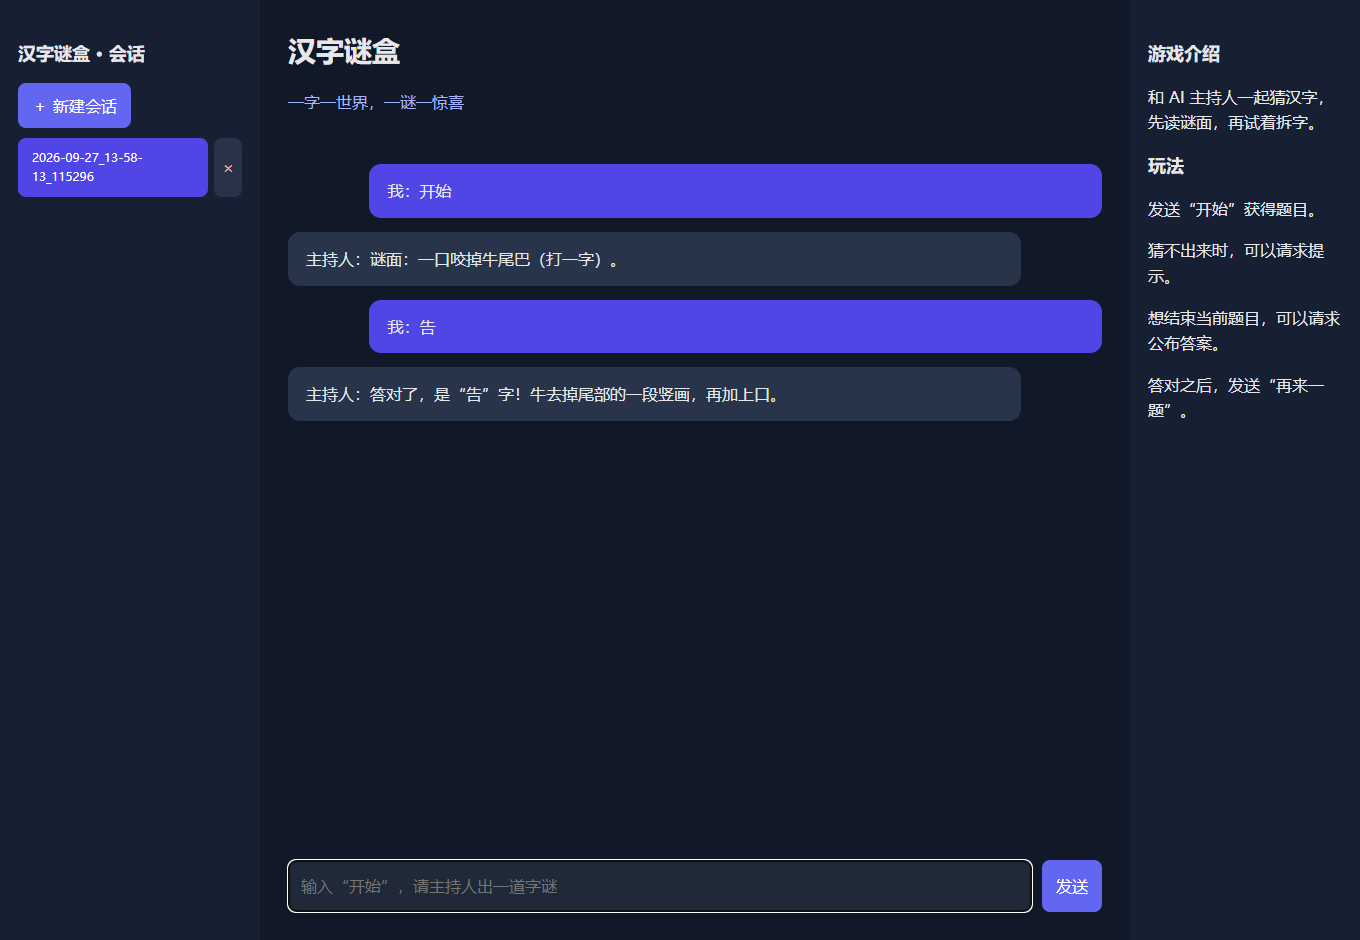

*补充参考页面的本地联调效果：AI 回复使用模拟数据，展示会话与多轮消息流程。*

图书系统检查普通会员和 VIP 上限、库存、本人归还与重启恢复；Web 项目检查五个接口、消息历史、输入验证、文件保存与错误状态。真实 DeepSeek 响应内容和当前账号的服务可用性，需要你配置后实际运行确认。

## 十九、本章复习与排错

### 1. 把知识连成一条线

```text
类组织属性与行为
    → 封装让调用方使用明确接口
    → 继承复用共同部分
    → 重写让子类调整行为
    → 多态让同一调用适应不同对象
    → FastAPI 把 Python 行为提供为 HTTP 接口
    → 前端通过接口操作业务与数据
    → JSON 保留历史，日志与异常处理帮助定位问题
```

### 2. 讲义核心问题

| 问题 | 回答要点 |
| --- | --- |
| 什么是封装 | 把数据和操作放进类，通过必要接口使用内部实现 |
| 公共和私有怎样区分 | 双前导下划线触发名称改写，不是严格权限控制 |
| 怎样继承父类 | `class Child(Parent):` |
| 什么是方法重写 | 子类定义同名方法，提供不同实现 |
| 如何调用父类逻辑 | `super().方法(...)`，或明确使用父类名调用 |
| 多继承同名方法如何查找 | 依据 MRO，用 __mro__ 或 mro() 查看 |
| 什么是多态 | 同一调用对不同对象产生不同表现 |
| 什么是鸭子类型 | 关注对象提供的行为，不要求共同继承关系 |
| 普通与默认 VIP 的借阅上限 | 3 本与 7 本 |
| 网站主要由什么组成 | 前端、服务端、数据存储 |
| HTML、CSS、JS 的职责 | 结构、样式、交互 |
| FastAPI 如何定义接口 | 应用对象 + 路径装饰器 + 处理函数 |
| REST 本章强调什么 | URL 表达资源，HTTP 方法表达操作 |
| 如何接收 POST JSON | BaseModel 子类与相应类型的函数参数 |
| 如何让 AI 记住前一题 | 每轮请求带上当前会话的历史消息 |
| logging 比 print 多解决什么 | 级别控制、时间、来源位置和统一格式 |
| 正文 code 为 500 是否等于 HTTP 500 | 不等于，必须设置实际 HTTP 状态 |

### 3. 常见问题对照

| 现象 | 优先检查 |
| --- | --- |
| `AttributeError: ... model` | 类初始化的是 name 还是 model，是否混用了课件不同版本 |
| 创建子类时参数数量不对 | 是否补齐构造方法，是否按正确顺序传参 |
| 子类没有父类的某个实例属性 | 自定义 __init__ 后是否调用了父类初始化 |
| `fastapi` 或 `uvicorn` 命令不存在 | 是否安装对应依赖、是否使用正确环境；可用 python -m uvicorn |
| `Could not import module main` | 当前目录、文件名、导入依赖以及 main.py 中的错误 |
| static 目录或首页找不到 | 是否创建文件，目录是否与代码路径相符 |
| 访问接口得到 405 | 路径存在但请求方法不匹配，例如用 GET 访问只支持 POST 的接口 |
| 返回 422 | 对照请求模型检查必填字段、类型、长度和 JSON 格式 |
| 会话列表有 ID，但加载报错 | 对应 JSON 是否存在、是否损坏、结构是否正确 |
| 模型对话没有延续上文 | 是否使用同一会话 ID，是否发送完整的本会话历史 |
| 正文显示错误但浏览器认为成功 | 是否只改了业务 code，没有设置 HTTP 状态码 |
| 代码修改后接口不见了 | 是否重复创建 app，把原来注册好的对象覆盖了 |
| 中文在 JSON 文件里显示成转义 | 使用 UTF-8 和 ensure_ascii=False；转义显示本身不一定代表内容损坏 |

本章依据 70 页 PPT 整理，封面、目录与重复动画合并到对应章节，末页品牌结束页不单独展开。课件原始示例与必要补充均在正文标明，便于以后拿到完整配套资料后继续对照学习。